# Análisis multivariante de la gravedad de los accidentes de tráfico en Gran Bretaña (2005–2025)

Cuaderno de trabajo del Proyecto de Posgrado · Diplomado en Análisis de Datos · Universidad Católica Boliviana «San Pablo»
Autor: Iván Ricardo Castillo Fernández

## Presentación
El presente notebook documenta el proceso completo del estudio: obtención y verificación de los datos, análisis exploratorio,
construcción de variables, estimación de modelos, evaluación con datos no utilizados en el entrenamiento e interpretación de los
resultados. Las salidas de cada celda se conservan en el documento, por lo que puede revisarse sin necesidad de ejecutarlo.

**Fuente de datos.** Registro oficial de accidentes con víctimas (STATS19) del *Department for Transport* del Reino Unido, tablas de
colisiones y de vehículos, periodo 2005–2025, publicado bajo la licencia *Open Government Licence v3.0*.

**Pregunta de investigación.** ¿Qué variables (vía, entorno, hora, lugar, vehículos y conductores) explican en mayor medida la gravedad
de un accidente de tráfico y en qué medida se modifica el análisis al incorporar la información de los vehículos?

**Alcance.** Se analiza la gravedad de accidentes que ya ocurrieron. El estudio no pronostica accidentes futuros ni estima el riesgo de
circulación, pues no se dispone de datos de exposición (volumen de tráfico, kilómetros recorridos). Asimismo, la importancia estadística
de una variable no implica una relación causal.

| Apartado | Contenido |
|---|---|
| 1 | Datos: origen, verificación, distribución de la gravedad y cambios en el registro |
| 2 | Análisis exploratorio: patrones temporales, condiciones de la vía y distribución espacial |
| 3 | Variables y partición temporal de los datos |
| 4 | Modelos: versión A (con datos de vehículos), versión B (sin ellos) y comparación de algoritmos |
| 5 | Evaluación con años y zonas no utilizados en el entrenamiento, calibración y análisis por subgrupos |
| 6 | Interpretación de los modelos mediante valores SHAP |
| 7 | Resultados, conclusiones y limitaciones |

## 0. Configuración del entorno

In [1]:
import sys, warnings, time, subprocess
from pathlib import Path
warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib
from IPython.display import Image, display, Markdown

import features                      # se importa primero para que los objetos serializados se carguen correctamente
import config, dft, train, calibration
import figuras_claras as fc
from config import ACCIDENTS_PARQUET, MODELS, FIGURES
get_ipython().run_line_magic("matplotlib", "inline")   # el módulo de figuras fija un modo sin pantalla; se restablece el del cuaderno

REPORTS = ROOT / "reports"
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"font.family": "Arial", "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25})

_mostrar_figura = plt.show
def _mostrar_con_coma(*args, **kwargs):          # separador decimal en coma en los ejes de todas las figuras del cuaderno
    for n in plt.get_fignums():
        fc.coma_decimal(plt.figure(n))
    _mostrar_figura(*args, **kwargs)
plt.show = _mostrar_con_coma

def mostrar(nombre, ancho=950):
    display(Image(filename=str(FIGURES / nombre), width=ancho))

print("Directorio del proyecto:", ROOT)
print("Directorio de datos oficiales:", dft.OFICIAL)

Directorio del proyecto: C:\Users\IVAN\Documents\Kaggle\proyecto-1-accidentes-uk
Directorio de datos oficiales: C:\Users\IVAN\Documents\Kaggle\proyecto-1-accidentes-uk\data\oficial_dft


## 1. Datos

### 1.1 Origen de los datos y preparación
Los datos son publicados por el *Department for Transport* (DfT) del Reino Unido, que los recopila a partir de los informes de la policía de cada fuerza (registro STATS19). Se utilizan dos tablas y una guía de códigos:

| Archivo oficial | Contenido | Registros 2005–2025 | Uso |
|---|---|---|---|
| Colisiones | Un registro por accidente: ubicación, hora, vía y gravedad | 2.892.427 | Base principal del análisis |
| Vehículos | Un registro por vehículo implicado: tipo y características del conductor | 5.301.126 | Se resume en un registro por accidente (versión A) |
| Guía de datos (`data-guide-2025.xlsx`) | Tabla oficial de códigos y significados | — | Decodificación de las categorías |

El DfT publica además una tabla de víctimas que no se utiliza en este estudio. La preparación de los datos (lectura, selección del periodo, decodificación con la guía oficial, agregación de los vehículos por accidente y construcción de variables) fue realizada por el autor mediante el módulo `src/dft.py`; los archivos se encuentran en `data/oficial_dft/`.

Como control de integridad, se comprueba que el número de accidentes del periodo 2005–2025 en el archivo oficial coincide con el de la base procesada.

In [2]:
raw = pd.read_csv(dft.COLLISIONS_CSV, usecols=["collision_year"])
n_oficial = int(raw["collision_year"].between(dft.YEAR_MIN, dft.YEAR_MAX).sum())
a = pd.read_parquet(ACCIDENTS_PARQUET)
print(f"Accidentes 2005–2025 en el archivo oficial : {format(n_oficial, ',').replace(',', '.')}")
print(f"Accidentes en la base procesada            : {format(len(a), ',').replace(',', '.')}")
assert n_oficial == len(a), "El número de registros no coincide con el archivo oficial."
print("Verificación superada. Periodo:", int(a.Year.min()), "–", int(a.Year.max()))

Accidentes 2005–2025 en el archivo oficial : 2.892.427
Accidentes en la base procesada            : 2.892.427
Verificación superada. Periodo: 2005 – 2025


### 1.2 Estructura de la base y datos ausentes

*Tabla 1. Variables de la base procesada, tipo de dato y porcentaje de valores ausentes.*

In [3]:
info = pd.DataFrame({"tipo": a.dtypes.astype(str), "% ausentes": (a.isna().mean() * 100).round(2), "ejemplo": a.iloc[0].astype(str)})
display(info)

,tipo,% ausentes,ejemplo
Accident_Index,str,0.00,2005620129234
Year,int16,0.00,2005
Accident_Severity,category,0.00,Slight
Date,datetime64[us],0.00,2005-04-01 00:00:00
Time,str,0.00,17:50
Latitude,float64,0.01,51.478541
Longitude,float64,0.01,-3.702931
Police_Force,int16,0.00,62
Number_of_Vehicles,int64,0.00,2
Number_of_Casualties,int64,0.00,3


Las coordenadas geográficas (`Latitude`, `Longitude`) presentan una proporción reducida de datos ausentes (Tabla 1), lo que permite el análisis espacial.
Las categorías declaradas como desconocidas en la guía oficial se tratan como valores ausentes y no se imputan.

### 1.3 Distribución de la gravedad
Cada accidente se clasifica en tres niveles: leve, grave o mortal. La proporción de accidentes mortales es reducida, situación conocida como
desbalance de clases. En este contexto la exactitud (*accuracy*) es una medida inadecuada, dado que un clasificador que asignara siempre la
categoría «leve» obtendría un valor elevado sin aportar información. Por ello se emplean métricas específicas para clases desbalanceadas
(macro-F1, precisión promedio y medidas de calibración).

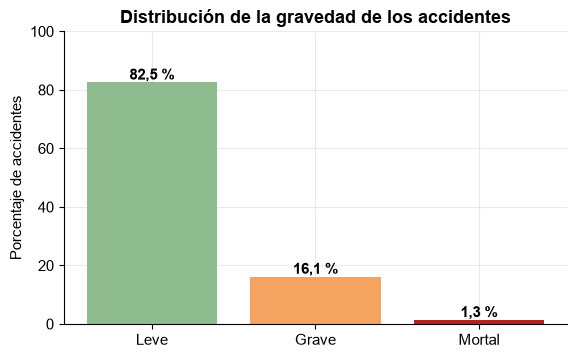

Proporción de accidentes mortales: 1,34 %


In [4]:
orden = ["Slight", "Serious", "Fatal"]; nombres = ["Leve", "Grave", "Mortal"]
pct = a["Accident_Severity"].value_counts(normalize=True).reindex(orden) * 100
fig, ax = plt.subplots(figsize=(6.5, 3.8))
b = ax.bar(nombres, pct.values, color=["#8fbc8f", "#f4a460", "#b22222"])
for r, v in zip(b, pct.values): ax.text(r.get_x() + r.get_width()/2, v + 1, f"{v:.1f} %".replace(".", ","), ha="center", fontweight="bold")
ax.set_ylabel("Porcentaje de accidentes"); ax.set_ylim(0, 100); ax.set_title("Distribución de la gravedad de los accidentes")
plt.show()
print("Proporción de accidentes mortales:", f"{pct['Fatal']:.2f} %".replace(".", ","))

*Figura 1. Distribución porcentual de los accidentes según su gravedad, 2005–2025. Fuente: elaboración propia con datos del DfT.*

### 1.4 Cambio en el sistema de registro de la gravedad
A partir de 2016, numerosas fuerzas policiales sustituyeron la clasificación de la gravedad basada en la valoración del agente por un sistema
basado en las lesiones (*injury-based reporting*). Este cambio incrementa la proporción de accidentes clasificados como graves sin que
necesariamente varíe la situación real en las vías. Para corregirlo, el DfT publica una gravedad ajustada, aplicable a los accidentes no mortales.

La Figura 2 contrasta, en el panel izquierdo, la proporción de accidentes graves según el registro original y según la serie ajustada; el panel
derecho presenta la proporción de accidentes registrados por lesiones y el número anual de accidentes mortales.

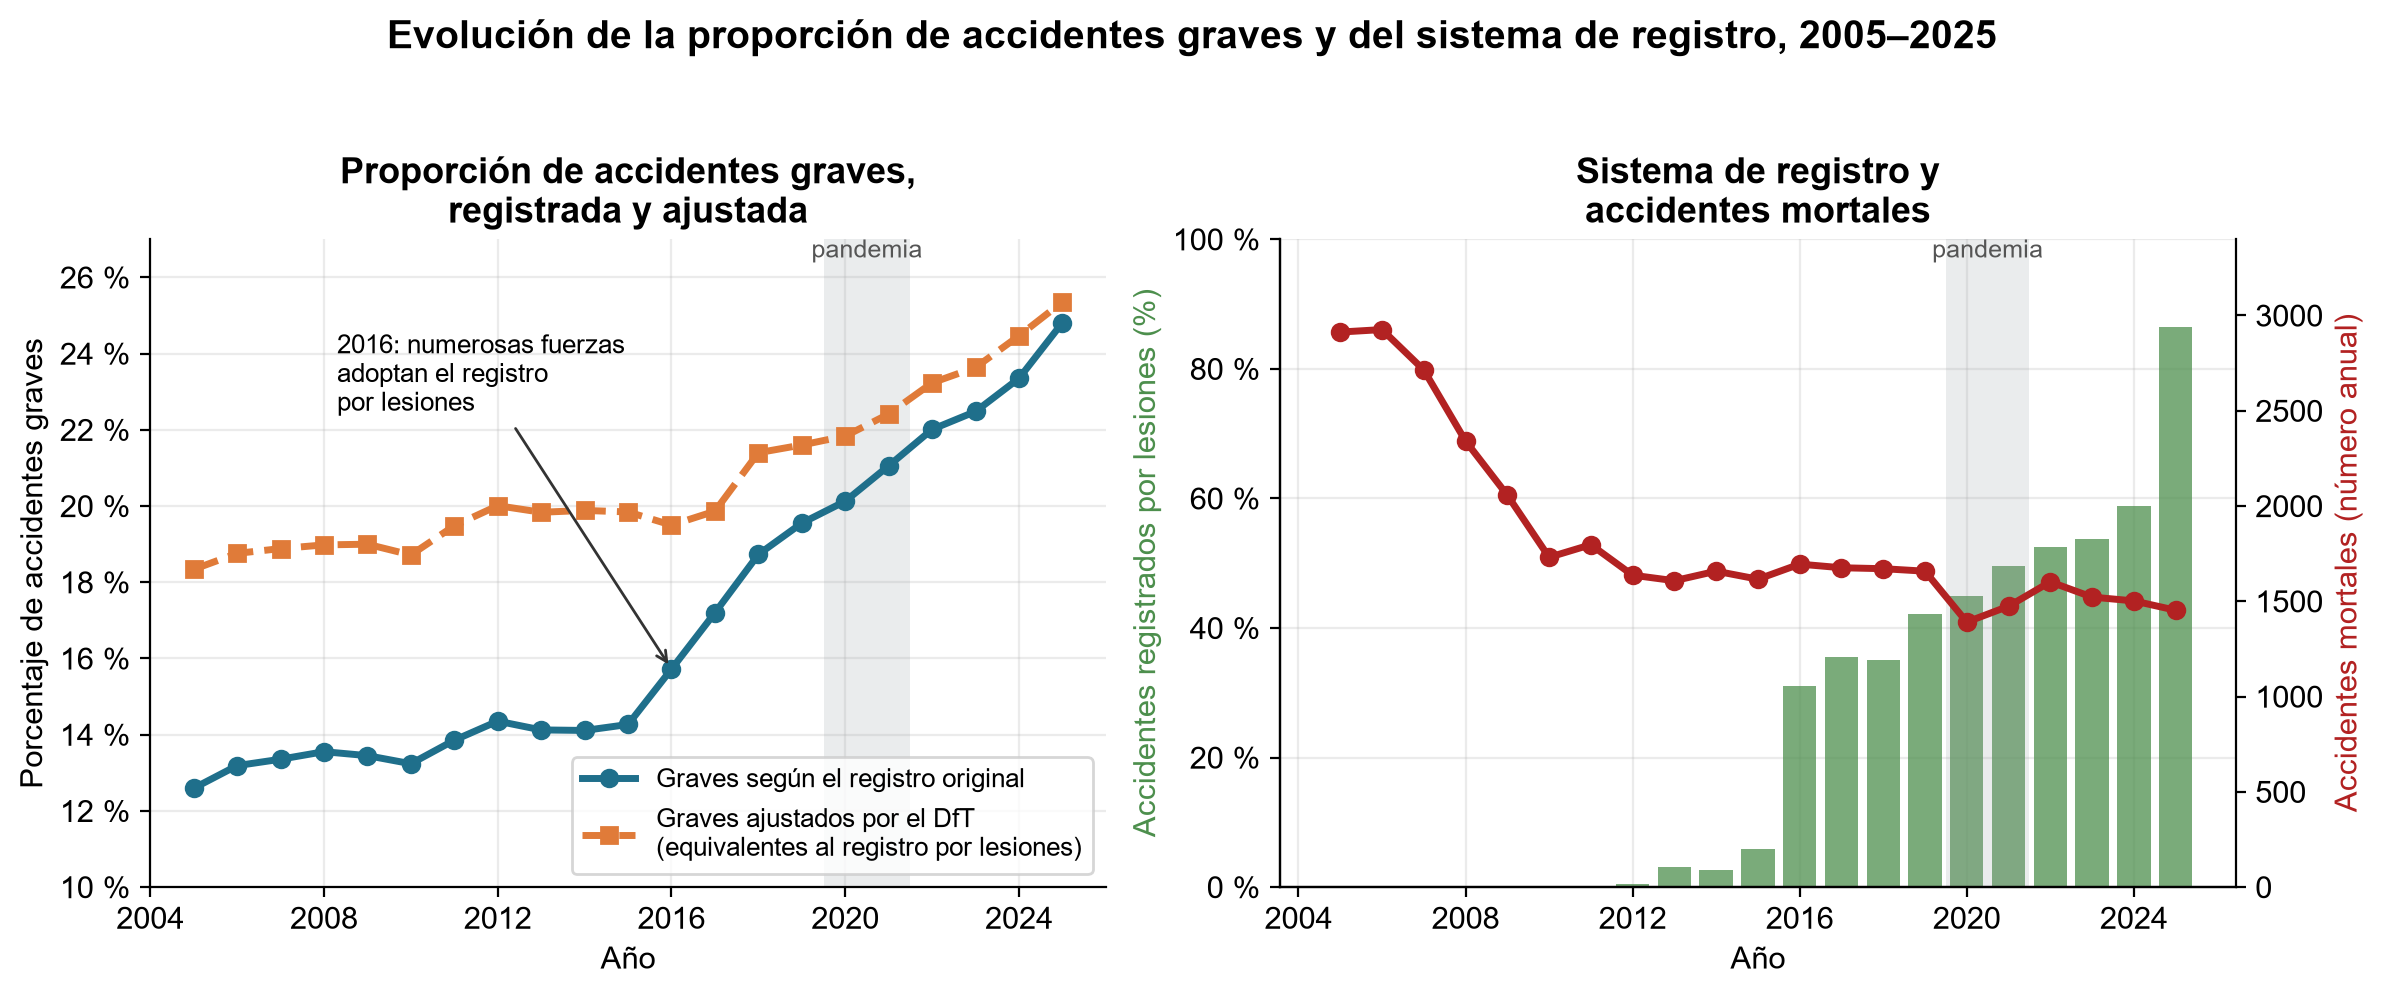

,rep,aj,ib,mort
Year,,,,
2014,14.11,19.88,2.71,1658
2015,14.27,19.84,5.88,1616
2016,15.72,19.50,31.03,1695
2017,17.20,19.86,35.44,1676
2018,18.73,21.40,35.04,1671
2019,19.55,21.60,42.12,1658
2020,20.13,21.84,44.91,1391
2021,21.06,22.41,49.62,1474
2022,22.01,23.23,52.57,1602


In [5]:
res = fc.f2_evolucion(a)
mostrar("F2_evolucion_graves.png", 1000)
display(res.round(2).tail(12))

*Figura 2. Evolución de la proporción de accidentes graves (registrada y ajustada) y del sistema de registro, 2005–2025. Fuente: elaboración propia con datos del DfT.*

Hasta 2017, buena parte del incremento de los accidentes graves registrados coincide con el cambio de sistema de registro, pues la serie ajustada por el DfT permanece prácticamente estable. A partir de 2018 esa serie también aumenta, por lo que el cambio de registro no es la única explicación. En consecuencia, el sistema de registro se incorpora como variable del modelo y la calibración se realiza de forma diferenciada
según dicho sistema (apartado 5.6). A continuación se comprueba y se mide el efecto del cambio comparando fuerzas policiales.

#### Comprobación con las fuerzas policiales
Para verificar el cambio de registro y medir cuánto influye, se aprovecha que cada fuerza lo adoptó en un año distinto. Se comparan dos grupos con los datos del propio DfT:

- **Fuerzas que cambiaron (18):** pasaron de registrar casi todo según la valoración del agente (hasta 25 % por lesiones en 2013 y 2015) a registrar casi todo por lesiones (75 % o más en 2017). La mayoría lo hizo en 2016.
- **Fuerzas de control (16):** no cambiaron en ningún año hasta 2018 (0 % por lesiones).

Se excluyen las fuerzas escocesas, cuyos códigos cambiaron en 2019, y la fuerza que adoptó el sistema antes (código 45).

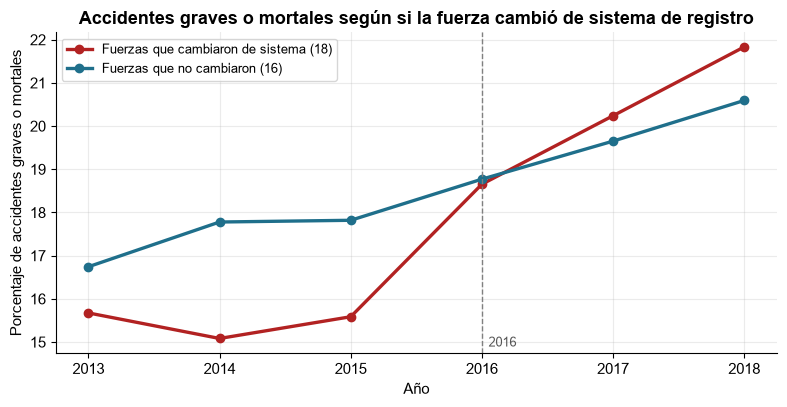

In [6]:
import cambio_registro_fuerzas as cr
fz = cr.analizar()
tabla_fz, efecto_fz = fz["tabla"], fz["did"]
fig, ax = plt.subplots(figsize=(8, 4.2))
for g_, col_, lab in (("cambian", "#b22222", f"Fuerzas que cambiaron de sistema ({fz['n_cambian']})"), ("control", "#1f6f8b", f"Fuerzas que no cambiaron ({fz['n_control']})")):
    s_ = tabla_fz[tabla_fz["grupo"] == g_]
    ax.plot(s_["Year"], s_["ksi_pct"], "o-", color=col_, lw=2.4, label=lab)
ax.axvline(2016, color="gray", ls="--", lw=1); ax.text(2016.05, ax.get_ylim()[0] + 0.15, "2016", fontsize=9, color="#555555")
ax.set_xlabel("Año"); ax.set_ylabel("Porcentaje de accidentes graves o mortales"); ax.legend(fontsize=9)
ax.set_title("Accidentes graves o mortales según si la fuerza cambió de sistema de registro")
ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True)); plt.tight_layout(); plt.show()

*Figura 3. Porcentaje de accidentes graves o mortales en las fuerzas que cambiaron de sistema de registro y en las que no, 2013–2018. Fuente: elaboración propia con datos del DfT.*

*Tabla 2. Efecto estimado del cambio de registro: diferencia entre antes (2013–2015) y después (2017–2018), con intervalo de confianza del 95 % calculado remuestreando fuerzas.*

In [7]:
display(efecto_fz.rename(columns={"medida": "medida", "valor": "valor", "ic95_inf": "IC95 inf", "ic95_sup": "IC95 sup"}).round(2).fillna("—"))

,medida,valor,IC95 inf,IC95 sup
0,Aumento en las fuerzas que cambiaron (puntos),5.57,—,—
1,Aumento en las fuerzas de control (puntos),2.66,—,—
2,Diferencia entre ambos: efecto estimado del ca...,2.91,0.78,5.03
3,Efecto según la serie ajustada del DfT (puntos),5.06,—,—


**Qué muestra**
- En las fuerzas que cambiaron, el porcentaje de accidentes graves o mortales era estable (15,7 %, 15,1 % y 15,6 % entre 2013 y 2015) y salta a 18,7 % en 2016, 20,2 % en 2017 y 21,8 % en 2018.
- En las fuerzas de control sube poco a poco (de 16,7 % en 2013 a 20,6 % en 2018), sin ningún salto en 2016.
- Los accidentes mortales, que no dependen de cómo se clasifique, no muestran un salto comparable: en 2018 están un 5 % (fuerzas que cambiaron) y un 7 % (control) por encima de 2015.

**Qué significa**
- El cambio de registro es real y tiene efecto: las fuerzas que cambiaron subieron 2,9 puntos más que las de control (IC95 de 0,8 a 5,0), de un aumento total de 5,6 puntos.
- Pero las fuerzas de control también suben (2,7 puntos), así que una parte del aumento no depende del registro.
- La serie ajustada del DfT atribuye al registro algo más (5,1 puntos). El efecto del cambio de registro está, por tanto, entre unos 3 y 5 puntos.

Esta comparación es aproximada: las fuerzas no se eligieron al azar y sus tendencias previas no son idénticas.

### 1.5 Variables excluidas por riesgo de fuga de información
Se denomina fuga de información a la utilización, durante el entrenamiento, de variables que no estarían disponibles en el momento de la
estimación o que contienen directamente la respuesta. Su inclusión produciría resultados artificialmente favorables. La Tabla 3 resume las
variables excluidas y el criterio aplicado.

*Tabla 3. Variables excluidas del análisis y justificación.*

In [8]:
fuga = pd.DataFrame([
    ("Number_of_Casualties", "Se conoce una vez ocurrido el accidente y está directamente relacionada con su gravedad."),
    ("Did_Police_Officer_Attend_Scene_of_Accident", "La asistencia policial depende de la gravedad del accidente."),
    ("Year", "Se excluye para que el modelo no dependa del año de ocurrencia."),
    ("Police_Force", "Los códigos de las fuerzas escocesas se modificaron en 2019, por lo que no son comparables entre periodos."),
    ("Variables de dinámica del choque (maniobra, punto de impacto, etc.)", "Describen el desarrollo del choque y no las condiciones previas."),
], columns=["Variable excluida", "Justificación"])
display(fuga)
print("Variables definidas como fuga en config.py:", config.LEAKAGE_COLUMNS)

,Variable excluida,Justificación
0,Number_of_Casualties,Se conoce una vez ocurrido el accidente y está...
1,Did_Police_Officer_Attend_Scene_of_Accident,La asistencia policial depende de la gravedad ...
2,Year,Se excluye para que el modelo no dependa del a...
3,Police_Force,Los códigos de las fuerzas escocesas se modifi...
4,"Variables de dinámica del choque (maniobra, pu...",Describen el desarrollo del choque y no las co...


Variables definidas como fuga en config.py: ['Number_of_Casualties', 'Did_Police_Officer_Attend_Scene_of_Accident']


## 2. Análisis exploratorio de datos
Este apartado es descriptivo y no incluye modelos. Se examina cuándo y dónde ocurren los accidentes y cuándo y dónde son más graves, distinguiendo
dos magnitudes diferentes: el número de accidentes y la proporción de accidentes graves o mortales.

### 2.1 Evolución anual

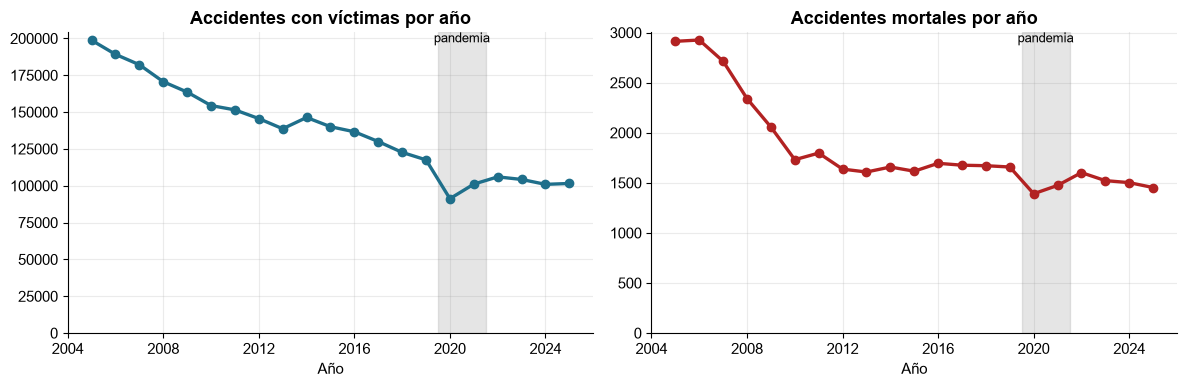

In [9]:
yr = a.groupby("Year").agg(accidentes=("Accident_Severity", "size"), mortales=("Accident_Severity", lambda s: (s == "Fatal").sum()))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col, color, tit in ((axes[0], "accidentes", "#1f6f8b", "Accidentes con víctimas por año"), (axes[1], "mortales", "#b22222", "Accidentes mortales por año")):
    ax.plot(yr.index, yr[col], "o-", color=color, lw=2.4)
    ax.axvspan(2019.5, 2021.5, color="gray", alpha=.2); ax.text(2020.5, ax.get_ylim()[1], "pandemia", ha="center", va="top", fontsize=9)
    ax.set_title(tit); ax.set_xlabel("Año"); ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True, nbins=7)); ax.set_ylim(0, None)
plt.tight_layout(); plt.show()

*Figura 4. Número anual de accidentes con víctimas y de accidentes mortales, 2005–2025. La banda gris señala el periodo 2020–2021. Fuente: elaboración propia con datos del DfT.*

El número de accidentes disminuye de forma sostenida a lo largo del periodo y presenta un descenso pronunciado en 2020, coincidente con las restricciones de
movilidad de la pandemia de COVID-19. Por este motivo, los años 2020 y 2021 se analizan como un periodo separado.

### 2.2 Distribución horaria

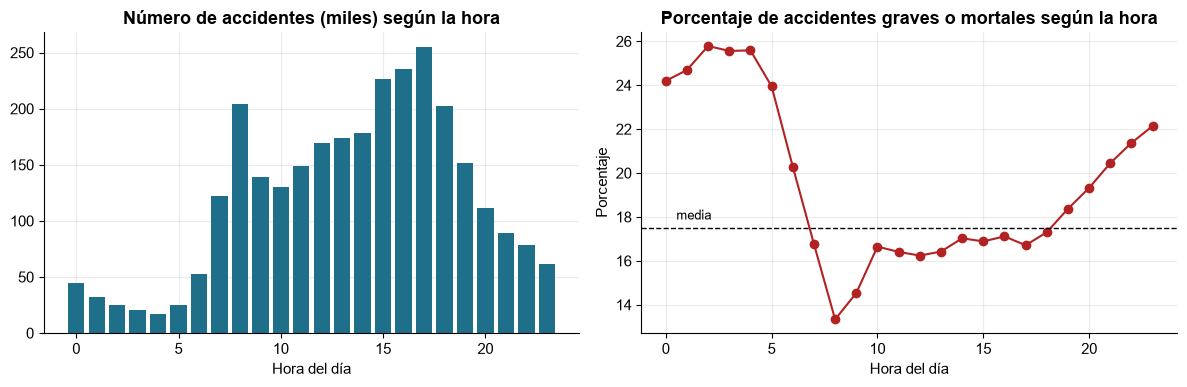

In [10]:
a["hora"] = pd.to_numeric(a["Time"].astype(str).str[:2], errors="coerce")
a["grave_o_mortal"] = (a["Accident_Severity"] != "Slight").astype(int)
h = a.groupby("hora").agg(n=("grave_o_mortal", "size"), r=("grave_o_mortal", "mean"))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(h.index, h["n"] / 1000, color="#1f6f8b"); axes[0].set_title("Número de accidentes (miles) según la hora"); axes[0].set_xlabel("Hora del día")
axes[1].plot(h.index, h["r"] * 100, "o-", color="#b22222"); axes[1].axhline(a["grave_o_mortal"].mean() * 100, color="k", ls="--", lw=1)
axes[1].set_title("Porcentaje de accidentes graves o mortales según la hora"); axes[1].set_xlabel("Hora del día"); axes[1].set_ylabel("Porcentaje")
axes[1].text(0.5, a["grave_o_mortal"].mean() * 100 + .4, "media", fontsize=9)
plt.tight_layout(); plt.show()

*Figura 5. Número de accidentes y porcentaje de accidentes graves o mortales según la hora del día, 2005–2025. La línea discontinua indica la media general. Fuente: elaboración propia con datos del DfT.*

La mayor concentración de accidentes se produce en las horas de mayor circulación (mañana y tarde), mientras que la proporción más elevada de accidentes graves
o mortales corresponde a la madrugada. Ambas magnitudes no evolucionan de forma paralela, lo que justifica analizarlas por separado.

### 2.3 Gravedad según las condiciones de la vía y del entorno

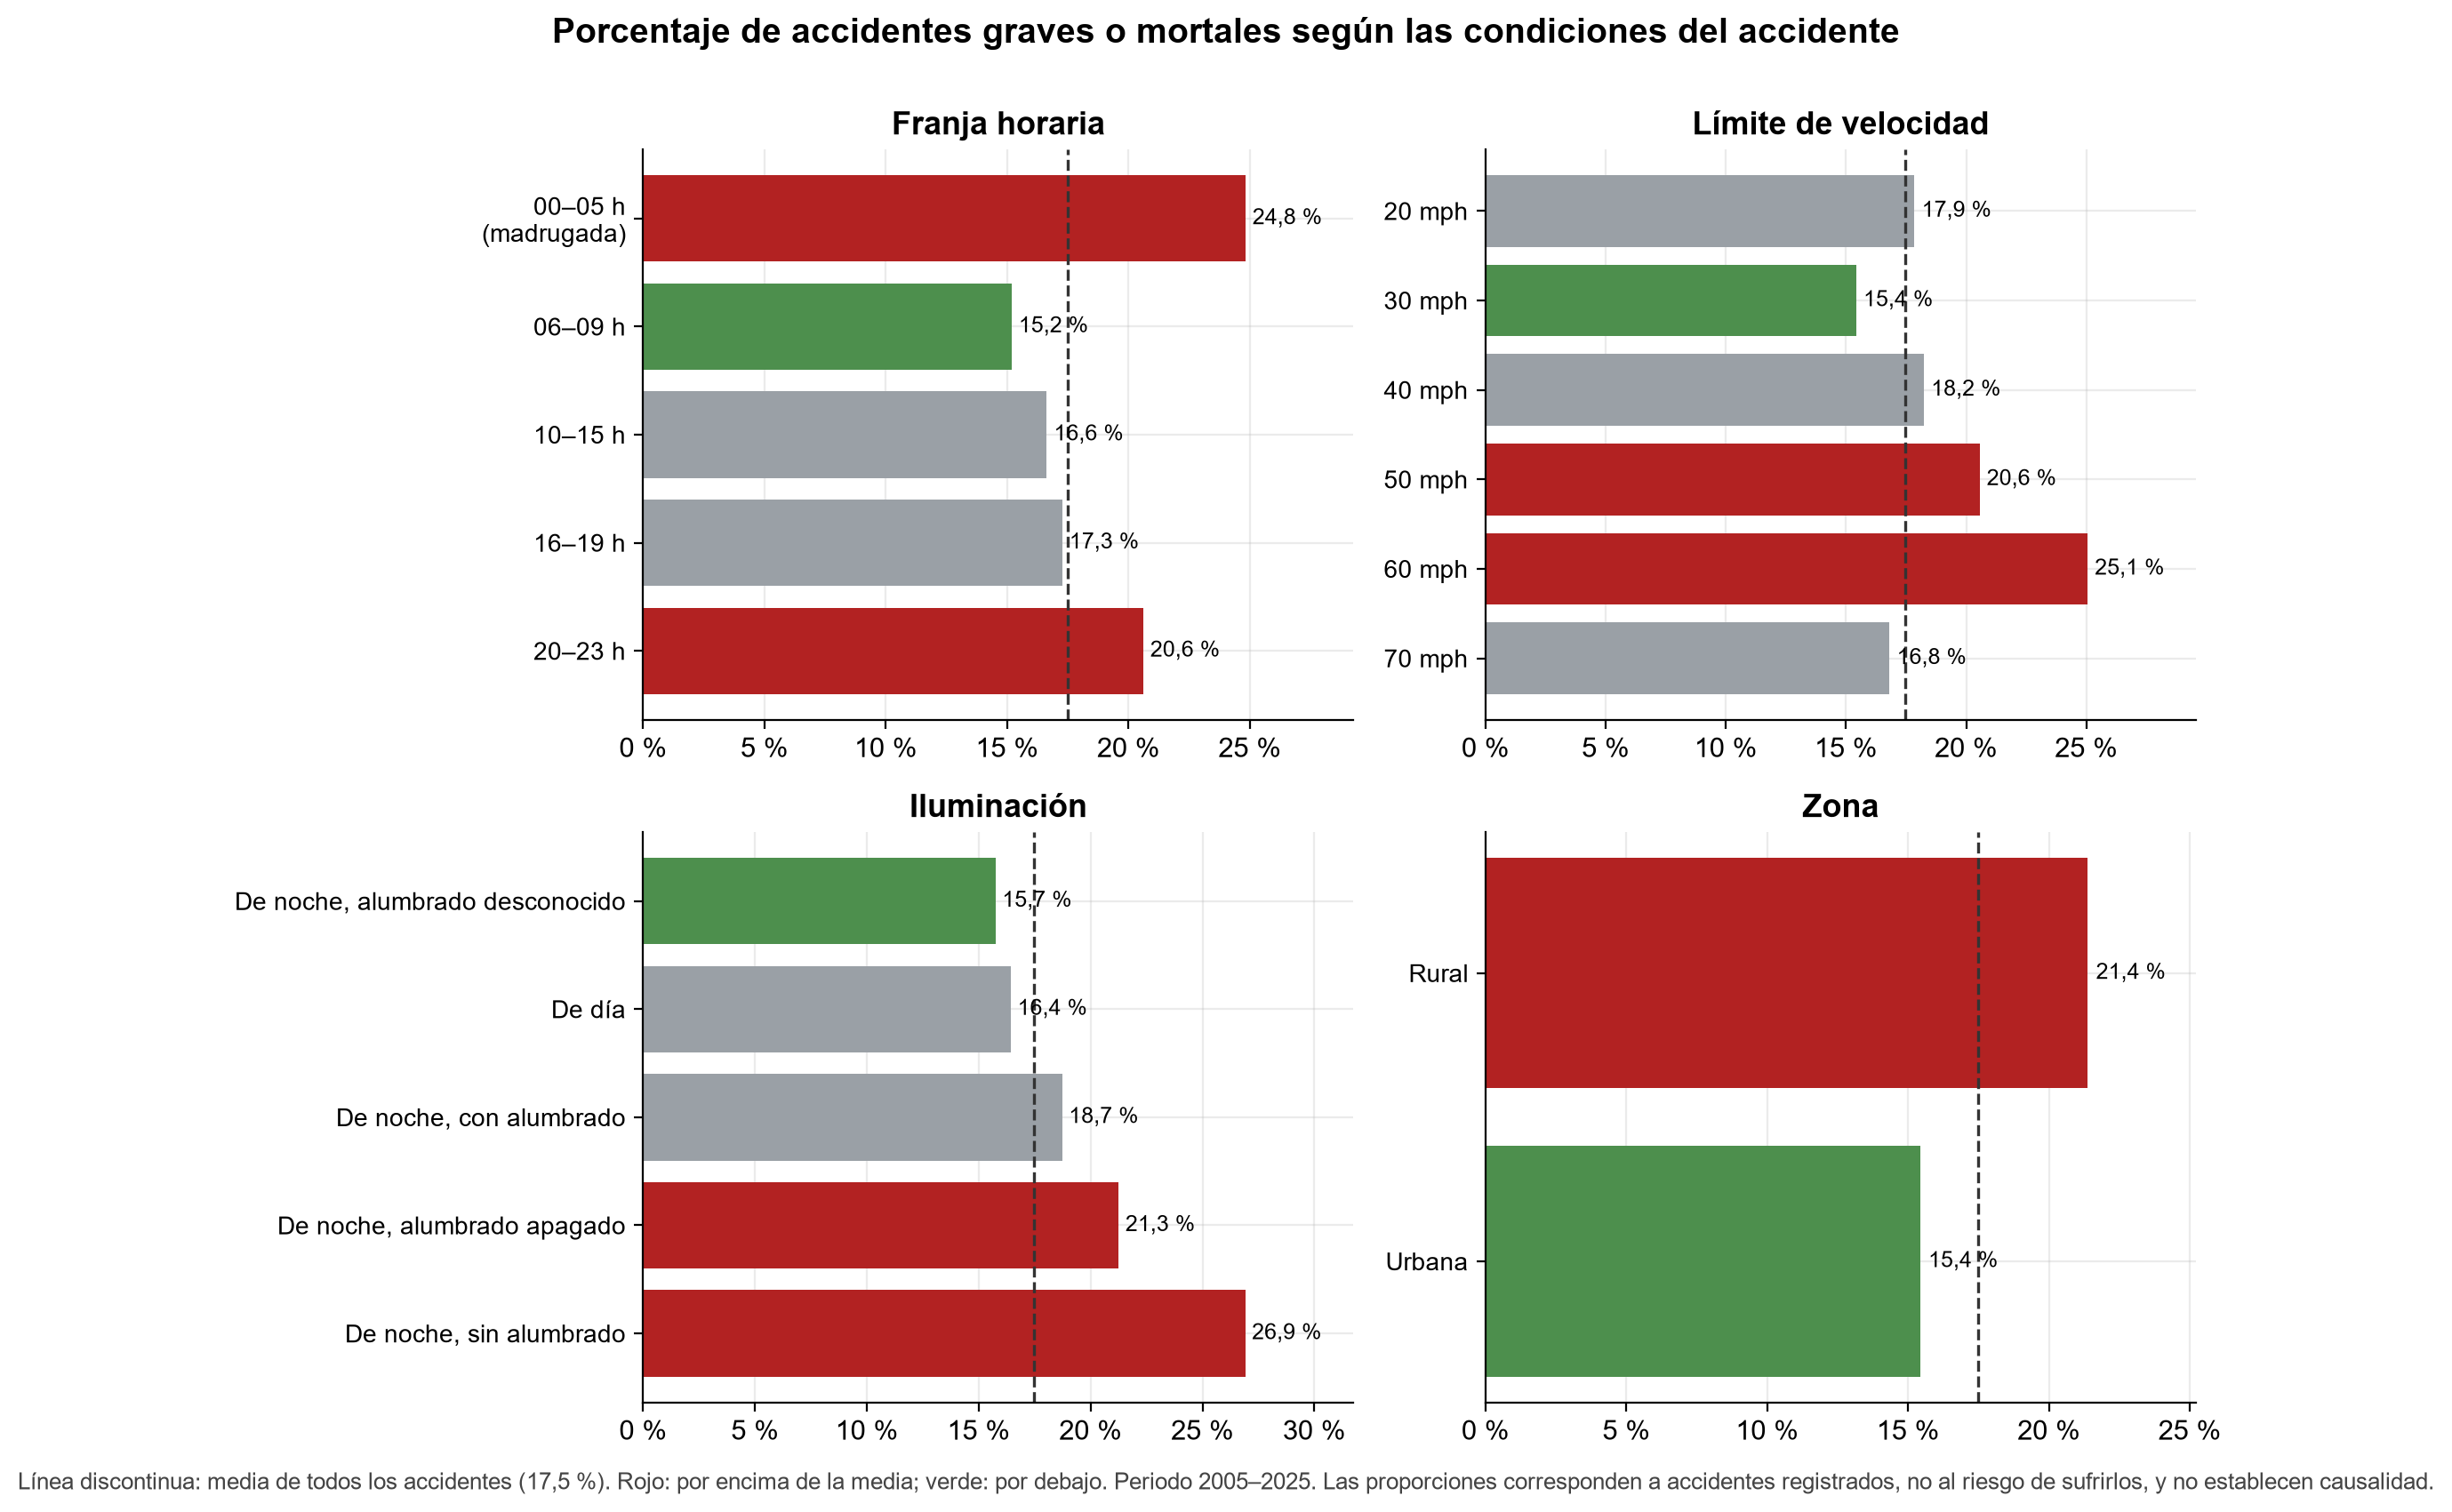

In [11]:
fc.f1_condiciones(a)
mostrar("F1_gravedad_por_condicion.png", 1000)

*Figura 6. Porcentaje de accidentes graves o mortales según franja horaria, límite de velocidad, iluminación y tipo de zona. Fuente: elaboración propia con datos del DfT.*

Las proporciones corresponden al conjunto de accidentes registrados y no al riesgo de sufrir un accidente; tampoco permiten establecer relaciones causales. Variables como
el límite de velocidad, el tipo de zona y la iluminación están asociadas entre sí, de modo que su efecto no puede aislarse mediante comparaciones univariantes. Esta
limitación motiva el empleo de técnicas multivariantes, que consideran simultáneamente el conjunto de variables.

### 2.4 Distribución espacial
El territorio se divide en celdas de aproximadamente 5 km y se calcula, para aquellas con un número suficiente de accidentes, la proporción de accidentes
graves o mortales. El tamaño de cada punto es proporcional al número de accidentes de la celda.

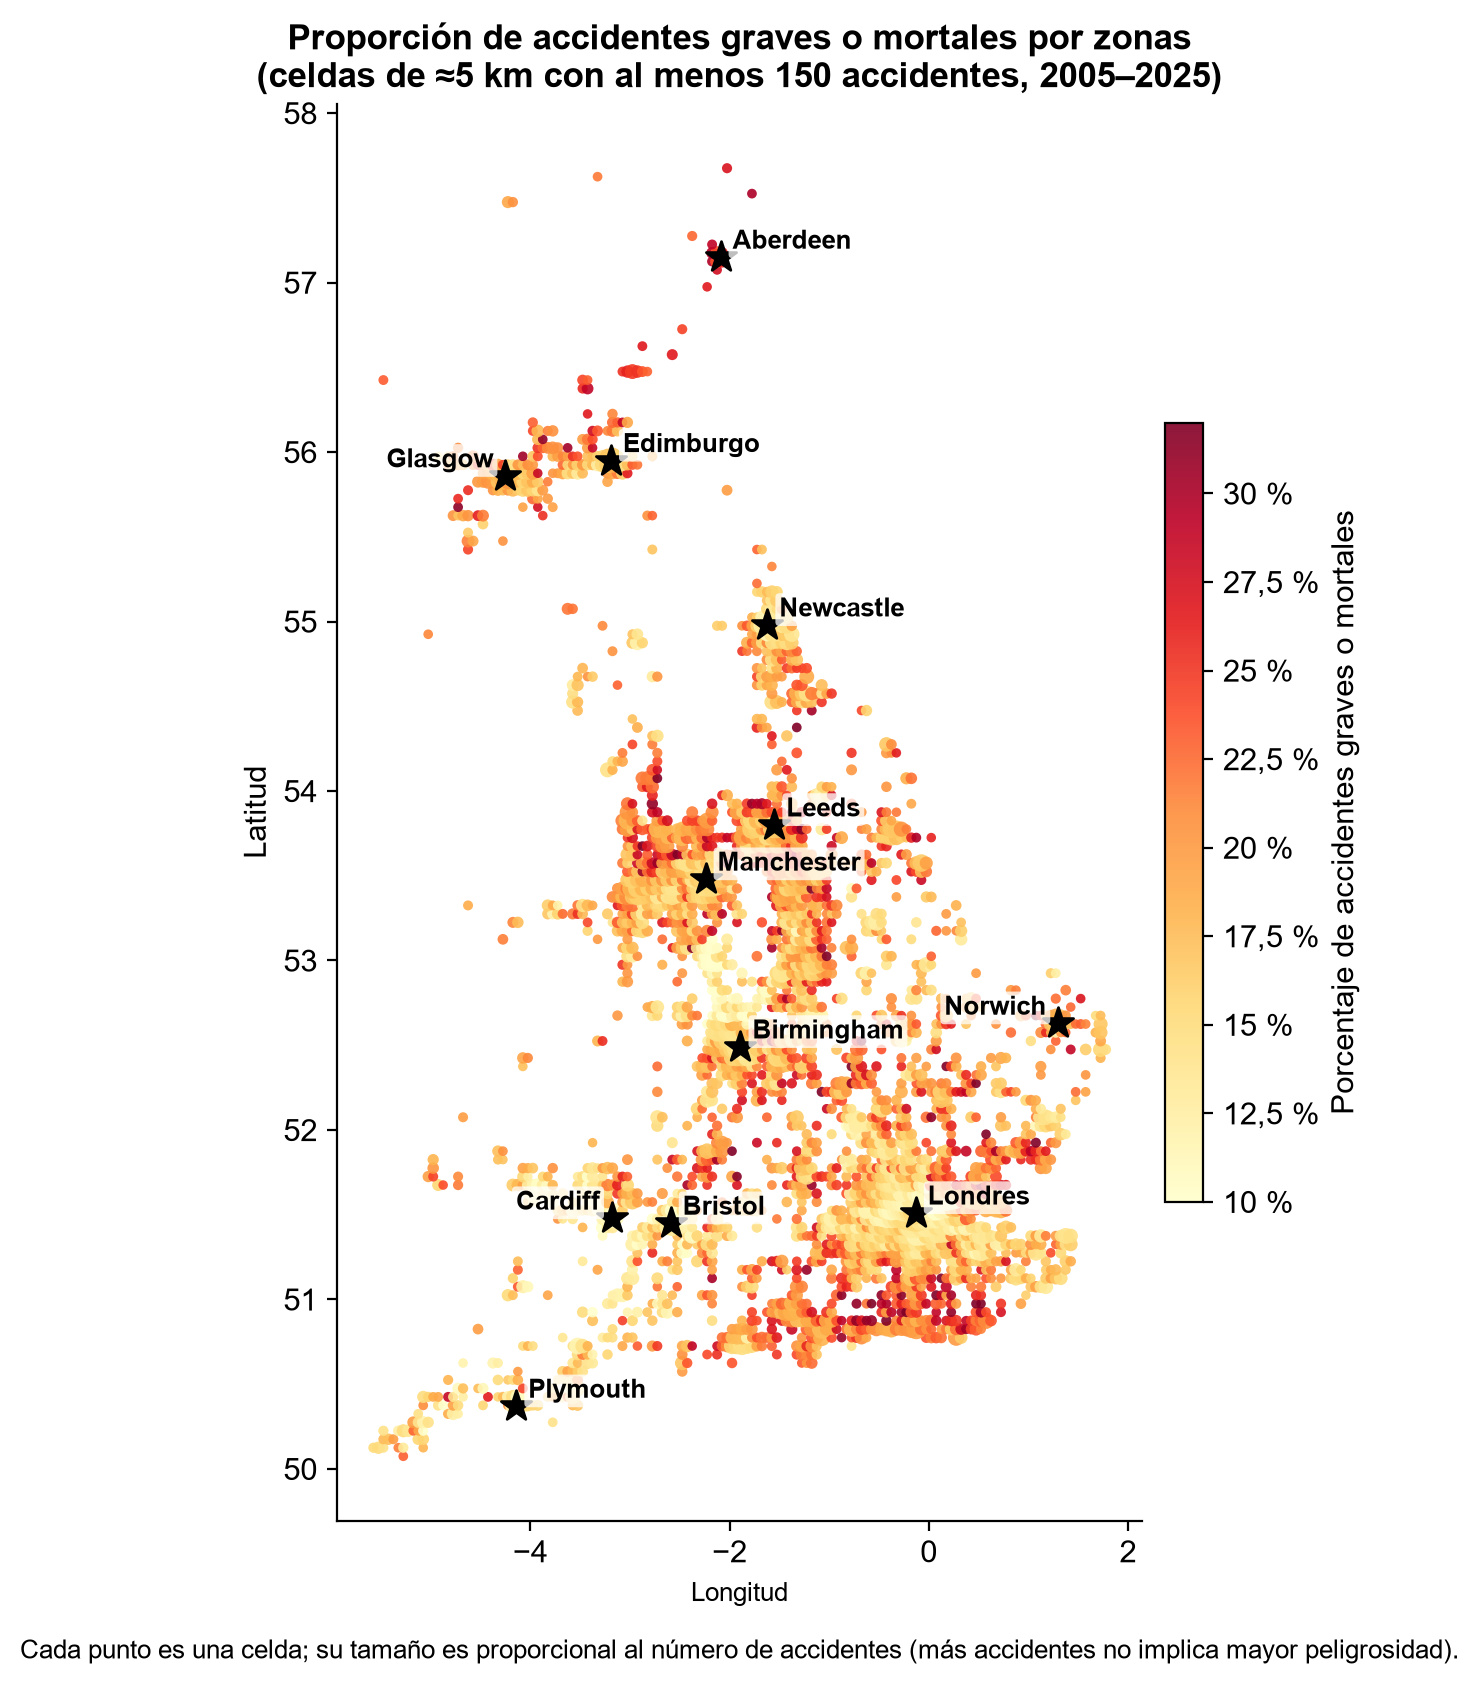

In [12]:
fc.f8_mapa()
mostrar("F8_mapa_proporcion.png", 700)

*Figura 7. Proporción de accidentes graves o mortales por celdas de aproximadamente 5 km (celdas con al menos 150 accidentes), 2005–2025. Fuente: elaboración propia con datos del DfT.*

Para valorar si las zonas que destacan en un periodo mantienen su posición en otros, se calculó la correlación entre periodos de dos magnitudes: el número de accidentes
y la proporción de accidentes graves de cada celda.

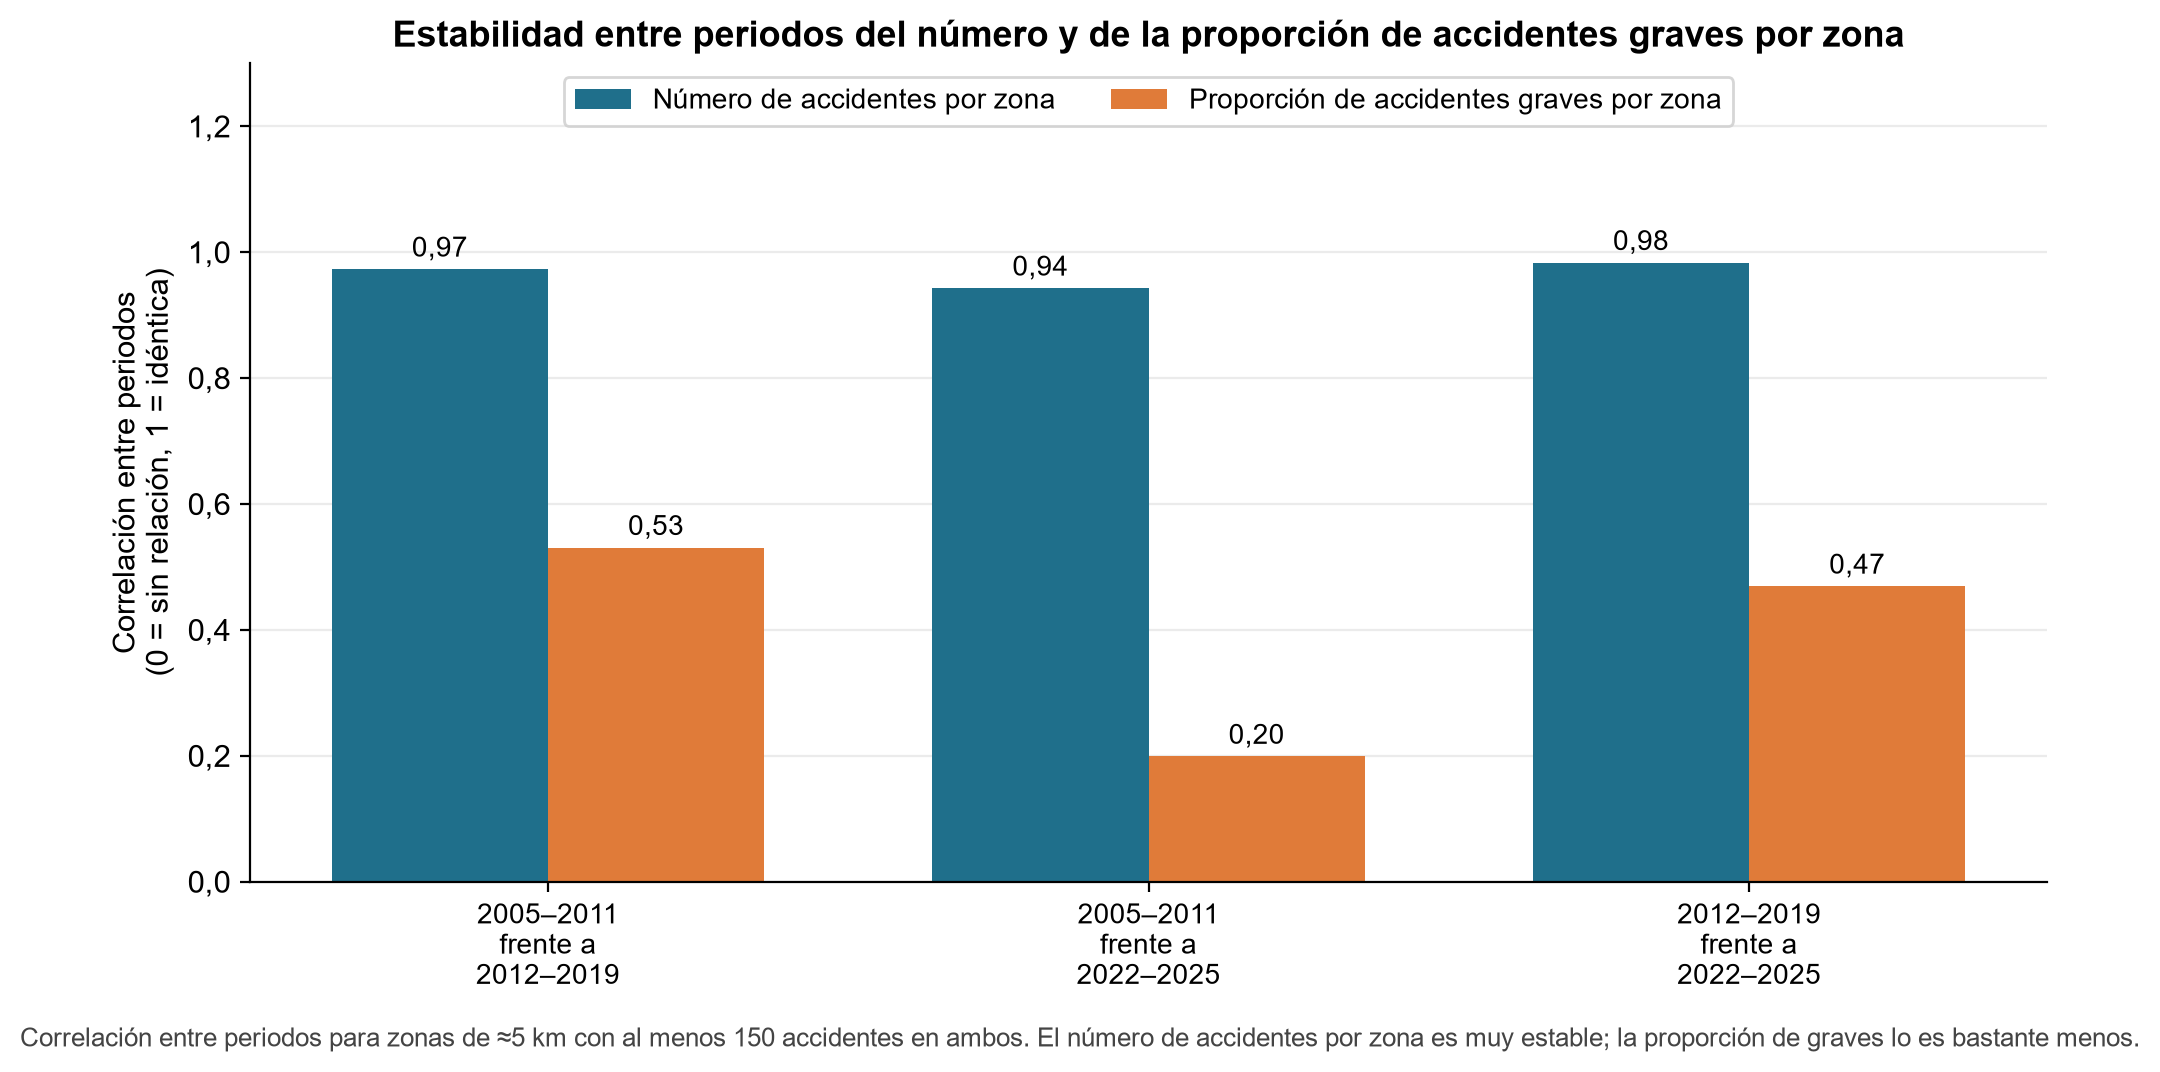

In [13]:
fc.f9_estabilidad()
mostrar("F9_estabilidad_zonas.png", 850)

*Figura 8. Correlación entre periodos del número de accidentes y de la proporción de accidentes graves por celda. Fuente: elaboración propia con datos del DfT.*

La distribución del número de accidentes por zona es muy estable entre periodos, mientras que la proporción de accidentes graves lo es considerablemente menos. En consecuencia, una
clasificación de zonas según la proporción de accidentes graves debe interpretarse con cautela, ya que es más sensible al periodo y al tamaño de la muestra.

## 3. Variables y partición temporal

### 3.1 Partición de los datos por años
La evaluación se diseña de manera que reproduzca un uso real: los modelos se entrenan con los años más antiguos y se evalúan con años posteriores, que no intervienen
en el entrenamiento ni en el ajuste. Una partición aleatoria, o el entrenamiento con todos los años, impediría comprobar el comportamiento del modelo ante datos nuevos y
conduciría a resultados excesivamente favorables. Los modelos se fijan antes de utilizar los conjuntos de evaluación.

*Tabla 4. Partición temporal de los datos y composición de cada conjunto.*

In [14]:
d, num, cat = train.load_splits()
etiquetas = {"train": "Entrenamiento", "val": "Validación (ajustes)", "test": "Prueba", "holdout": "Evaluación principal (reserva)",
             "estres": "Pandemia", "post": "Años posteriores"}
reparto = pd.DataFrame({etiquetas[k]: {"años": (f"{int(v.Year.min())}" if v.Year.min() == v.Year.max() else f"{int(v.Year.min())}–{int(v.Year.max())}"), "accidentes": f"{len(v):,}".replace(",", "."),
                                       "% graves o mortales": round(v.ksi.mean() * 100, 1), "% mortales": round((v.severity == 2).mean() * 100, 2)}
                        for k, v in d.items()}).T
display(reparto)

,años,accidentes,% graves o mortales,% mortales
Entrenamiento,2005–2014,1.640.486,14.8,1.3
Validación (ajustes),2015,140.029,15.4,1.15
Prueba,2016–2017,266.577,17.7,1.26
Evaluación principal (reserva),2018–2019,240.088,20.5,1.39
Pandemia,2020–2021,192.255,22.1,1.49
Años posteriores,2022–2025,412.678,24.6,1.47


### 3.2 Variables empleadas
Las variables se construyen evitando el uso de información posterior. Todo lo que se estima a partir de los datos (agrupación geográfica, densidad y proporción histórica de accidentes
graves por celda) se calcula exclusivamente con los años de entrenamiento (`src/features.py`). Se definen dos versiones del análisis:

- **Versión A (con vehículos):** variables de la vía, el entorno, la hora y el lugar, más las características de los vehículos y conductores implicados.
- **Versión B (sin vehículos):** únicamente variables de la vía, el entorno, la hora y el lugar.

*Tabla 5. Variables de los modelos, agrupadas por categoría.*

In [15]:
A = joblib.load(MODELS / "modelo_con_vehiculos.joblib"); B = joblib.load(MODELS / "modelo_sin_vehiculos.joblib")
filas = []
extra_grupo = {"hour_sin": "Momento", "hour_cos": "Momento", "Latitude": "Lugar", "Longitude": "Lugar"}
extra_nombre = {"hour_sin": "Hora del día (componente seno)", "hour_cos": "Hora del día (componente coseno)", "Latitude": "Latitud", "Longitude": "Longitud"}
for v in A["columns"]:
    grupo = fc.GRUPO_DE.get(v, extra_grupo.get(v, "Otros"))
    filas.append((v, fc.NOMBRES.get(v, extra_nombre.get(v, v)), grupo, "A y B" if v in B["columns"] else "solo A"))
tabla_vars = pd.DataFrame(filas, columns=["variable", "significado", "grupo", "en modelo"])
print(f"Versión A: {len(A['columns'])} variables · Versión B: {len(B['columns'])} variables")
display(tabla_vars.groupby("grupo").agg(variables=("variable", "count")).T)
display(tabla_vars.sort_values(["grupo", "variable"]).reset_index(drop=True))

Versión A: 37 variables · Versión B: 24 variables


grupo,Entorno,Lugar,Momento,Número de vehículos,Sistema de registro,Vehículos y conductores,Vía y cruce
variables,4,6,5,1,1,13,7


,variable,significado,grupo,en modelo
0,Light_Conditions,Iluminación,Entorno,A y B
1,Road_Surface_Conditions,Superficie de la vía,Entorno,A y B
2,Weather_Conditions,Clima,Entorno,A y B
3,is_dark,Oscuridad,Entorno,A y B
4,Latitude,Latitud,Lugar,A y B
5,Longitude,Longitud,Lugar,A y B
6,cell_density,Accidentes previos en la zona,Lugar,A y B
7,cell_ksi_rate,Proporción previa de graves en la zona,Lugar,A y B
8,dist_london_km,Distancia a Londres,Lugar,A y B
9,geo_cluster,Zona del país (agrupación),Lugar,A y B


## 4. Modelos

### 4.1 Diseño de la comparación
Se establecen dos comparaciones. La primera contrasta las versiones A y B, de modo que la diferencia de desempeño entre ambas permita estimar el aporte de los datos
de vehículos y conductores. La segunda compara tres algoritmos con las mismas variables y los mismos años: la regresión logística, técnica multivariante clásica que sirve
de referencia y es de fácil interpretación, y dos algoritmos de *boosting* (XGBoost y LightGBM), capaces de representar relaciones más complejas entre las variables.

Los modelos finales A y B emplean LightGBM y se entrenaron con los años 2005–2014 (`src/final_models.py`). En este cuaderno se cargan ya entrenados y no se modifican.

*Tabla 6. Configuración de los modelos finales.*

In [16]:
REENTRENAR = False      # si se establece True, se vuelven a entrenar A y B (proceso de varios minutos)
if REENTRENAR:
    import final_models; final_models.main()
resumen = pd.DataFrame({
    "Versión A (con vehículos)": {"variables": len(A["columns"]), "árboles": A["model"].best_iteration_, "umbral de alerta (mortales)": round(A["alert_threshold"], 4),
                                  "pesos de clase (leve, grave, mortal)": np.round(A["class_weights"], 2).tolist()},
    "Versión B (sin vehículos)": {"variables": len(B["columns"]), "árboles": B["model"].best_iteration_, "umbral de alerta (mortales)": round(B["alert_threshold"], 4),
                                  "pesos de clase (leve, grave, mortal)": np.round(B["class_weights"], 2).tolist()},
})
display(resumen)

,Versión A (con vehículos),Versión B (sin vehículos)
variables,37,24
árboles,166,109
umbral de alerta (mortales),0.0472,0.0593
"pesos de clase (leve, grave, mortal)","[1.0, 3.16, 10.0]","[1.0, 3.98, 15.85]"


### 4.2 Comparación de algoritmos

*Tabla 7. Macro-F1 de cada algoritmo según el periodo de evaluación.*

modelo,LightGBM,Regresión logística,XGBoost
conjunto,,,
estres 2020-21,0.4449,0.4204,0.4462
holdout 2018-19,0.4430,0.4255,0.4419
post 2022-25,0.4362,0.4081,0.4346
test 2016-17,0.4425,0.4194,0.4431


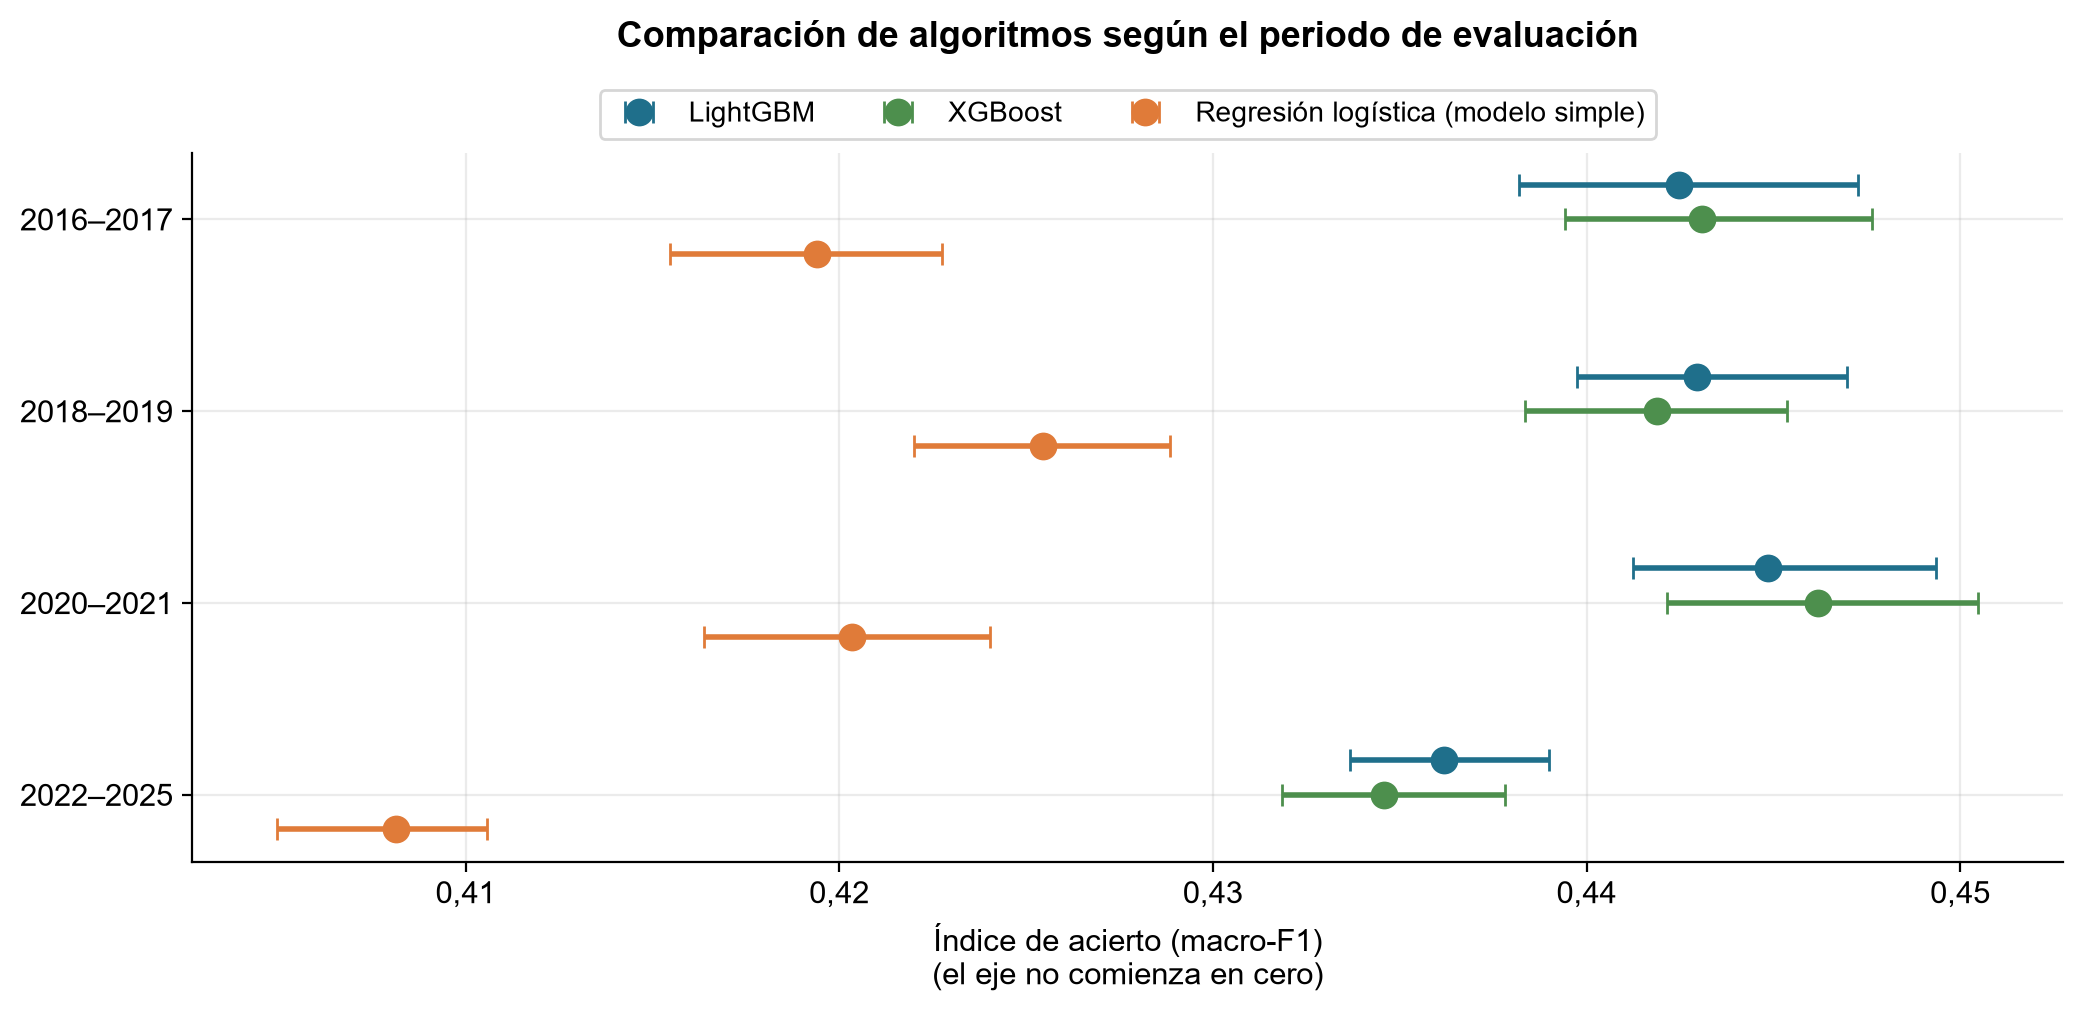

In [17]:
cmp = pd.read_csv(REPORTS / "comparacion_modelos.csv")
display(cmp.pivot(index="conjunto", columns="modelo", values="macro_f1").round(4))
fc.f11_algoritmos()
mostrar("F11_comparacion_algoritmos.png", 850)

*Figura 9. Macro-F1 de LightGBM, XGBoost y regresión logística con su intervalo de confianza del 95 %, según el periodo de evaluación. Fuente: elaboración propia con datos del DfT.*

*Tabla 8. Diferencias de macro-F1 de LightGBM respecto de los otros algoritmos, con intervalo de confianza del 95 % (remuestreo).*

In [18]:
display(pd.read_csv(REPORTS / "comparacion_contrastes.csv").round(4))

,conjunto,contraste,dif_macro_f1,ic95_inf,ic95_sup
0,test 2016-17,LightGBM − XGBoost,-0.0007,-0.0031,0.0015
1,test 2016-17,LightGBM − Regresión logística,0.0232,0.0188,0.0265
2,holdout 2018-19,LightGBM − XGBoost,0.0013,-0.0014,0.0040
3,holdout 2018-19,LightGBM − Regresión logística,0.0178,0.0140,0.0211
4,estres 2020-21,LightGBM − XGBoost,-0.0011,-0.0040,0.0021
5,estres 2020-21,LightGBM − Regresión logística,0.0250,0.0201,0.0293
6,post 2022-25,LightGBM − XGBoost,0.0016,-0.0005,0.0040
7,post 2022-25,LightGBM − Regresión logística,0.0283,0.0253,0.0315


LightGBM y XGBoost presentan un desempeño equivalente: los intervalos de confianza de sus diferencias incluyen el valor cero en todos los periodos. La regresión logística
obtiene valores inferiores en todos los casos, por lo que la mayor complejidad de los algoritmos de *boosting* se asocia con una mejora moderada.

## 5. Evaluación con datos no utilizados en el entrenamiento
La evaluación emplea accidentes reales posteriores al periodo de entrenamiento. Los resultados se acompañan de intervalos de confianza obtenidos por remuestreo (*bootstrap*) y
se interpretan en comparación con un modelo trivial que asignara siempre la categoría «leve».

### 5.1 Verificación con el periodo de evaluación principal (2018–2019)
Se calculan las predicciones directamente en este cuaderno con los modelos entrenados y se verifica que coinciden con los resultados almacenados.

In [19]:
ev = d["holdout"].reset_index(drop=True)
y = ev["severity"].values
models = {}
for nombre, b, color in (("A", A, fc.BLUE), ("B", B, fc.ORANGE)):
    p = b["model"].predict_proba(ev[b["columns"]])
    models[nombre] = (p, b, color)
    e = train.evaluate(y, p, b["class_weights"])
    guardado = pd.read_csv(REPORTS / "holdout_metricas.csv").query("modelo == @nombre and conjunto == 'holdout 2018-19'").iloc[0]
    assert np.isclose(e["macro_f1"], guardado["macro_f1"], atol=1e-6), "El resultado no coincide con el almacenado."
    print((f"Versión {nombre}: macro-F1 = {e['macro_f1']:.4f} (coincide con el resultado almacenado) · "
          f"AP mortales = {e['ap_fatal']:.4f} · sensibilidad en mortales (clase más probable) = {e['recall_fatal']:.3f}").replace(".", ","))
print(f"Accidentes evaluados: {format(len(y), ',').replace(',', '.')}")

Versión A: macro-F1 = 0,4430 (coincide con el resultado almacenado) · AP mortales = 0,0855 · sensibilidad en mortales (clase más probable) = 0,115


Versión B: macro-F1 = 0,4117 (coincide con el resultado almacenado) · AP mortales = 0,0582 · sensibilidad en mortales (clase más probable) = 0,114
Accidentes evaluados: 240.088


### 5.2 Resultados por periodo

*Tabla 9. Métricas de desempeño de las versiones A y B en cada periodo de evaluación (AP: precisión promedio).*

In [20]:
m = pd.read_csv(REPORTS / "holdout_metricas.csv")
ci = pd.read_csv(REPORTS / "holdout_ic95.csv").query("metrica == 'macro_f1'")
t = m[["modelo", "conjunto", "macro_f1", "ap_ksi", "ap_fatal", "alert_recall", "alert_precision", "ece_raw", "ece_recal", "n"]].merge(
    ci[["modelo", "conjunto", "ic95_inf", "ic95_sup"]], on=["modelo", "conjunto"]).rename(columns={
    "macro_f1": "macro-F1", "ap_ksi": "AP graves+mortales", "ap_fatal": "AP mortales", "alert_recall": "alerta: sensibilidad",
    "alert_precision": "alerta: precisión", "ece_raw": "error de calibración", "ece_recal": "error de calibración (recalibrado)",
    "ic95_inf": "IC95 inf", "ic95_sup": "IC95 sup"})
display(t.round(4))

,modelo,conjunto,macro-F1,AP graves+mortales,AP mortales,alerta: sensibilidad,alerta: precisión,error de calibración,error de calibración (recalibrado),n,IC95 inf,IC95 sup
0,A,val 2015,0.4514,0.3497,0.0804,0.3781,0.0800,0.0051,0.0138,140029,0.4461,0.4577
1,A,test 2016-17,0.4425,0.3652,0.0809,0.3228,0.0846,0.0147,0.0028,266577,0.4384,0.4466
2,A,holdout 2018-19,0.4430,0.3939,0.0855,0.3164,0.0956,0.0407,0.0258,240088,0.4396,0.4469
3,A,estres 2020-21,0.4449,0.4151,0.0957,0.2996,0.1056,0.0494,0.0341,192255,0.4408,0.4495
4,A,post 2022-25,0.4362,0.4277,0.0817,0.2691,0.0977,0.0657,0.0498,412678,0.4336,0.4391
5,B,val 2015,0.4139,0.2685,0.0510,0.1702,0.0800,0.0058,0.0145,140029,0.4095,0.4181
6,B,test 2016-17,0.4107,0.2869,0.0561,0.1516,0.0935,0.0208,0.0056,266577,0.4077,0.4138
7,B,holdout 2018-19,0.4117,0.3184,0.0582,0.1343,0.0968,0.0478,0.0269,240088,0.4083,0.4158
8,B,estres 2020-21,0.4142,0.3434,0.0637,0.1149,0.1019,0.0623,0.0413,192255,0.4100,0.4184
9,B,post 2022-25,0.4086,0.3617,0.0571,0.1028,0.0967,0.0790,0.0571,412678,0.4063,0.4116


El macro-F1 promedia el desempeño en las tres clases y toma el valor 1 ante una clasificación perfecta; el modelo trivial alcanza aproximadamente 0,3. La precisión promedio (AP) mide la capacidad
de ordenar los accidentes de mayor a menor gravedad. El modo de alerta marca un porcentaje reducido de accidentes como de mayor probabilidad de resultar mortales, con un umbral fijado en el año
de validación (2015).

### 5.3 Estabilidad del desempeño en el tiempo

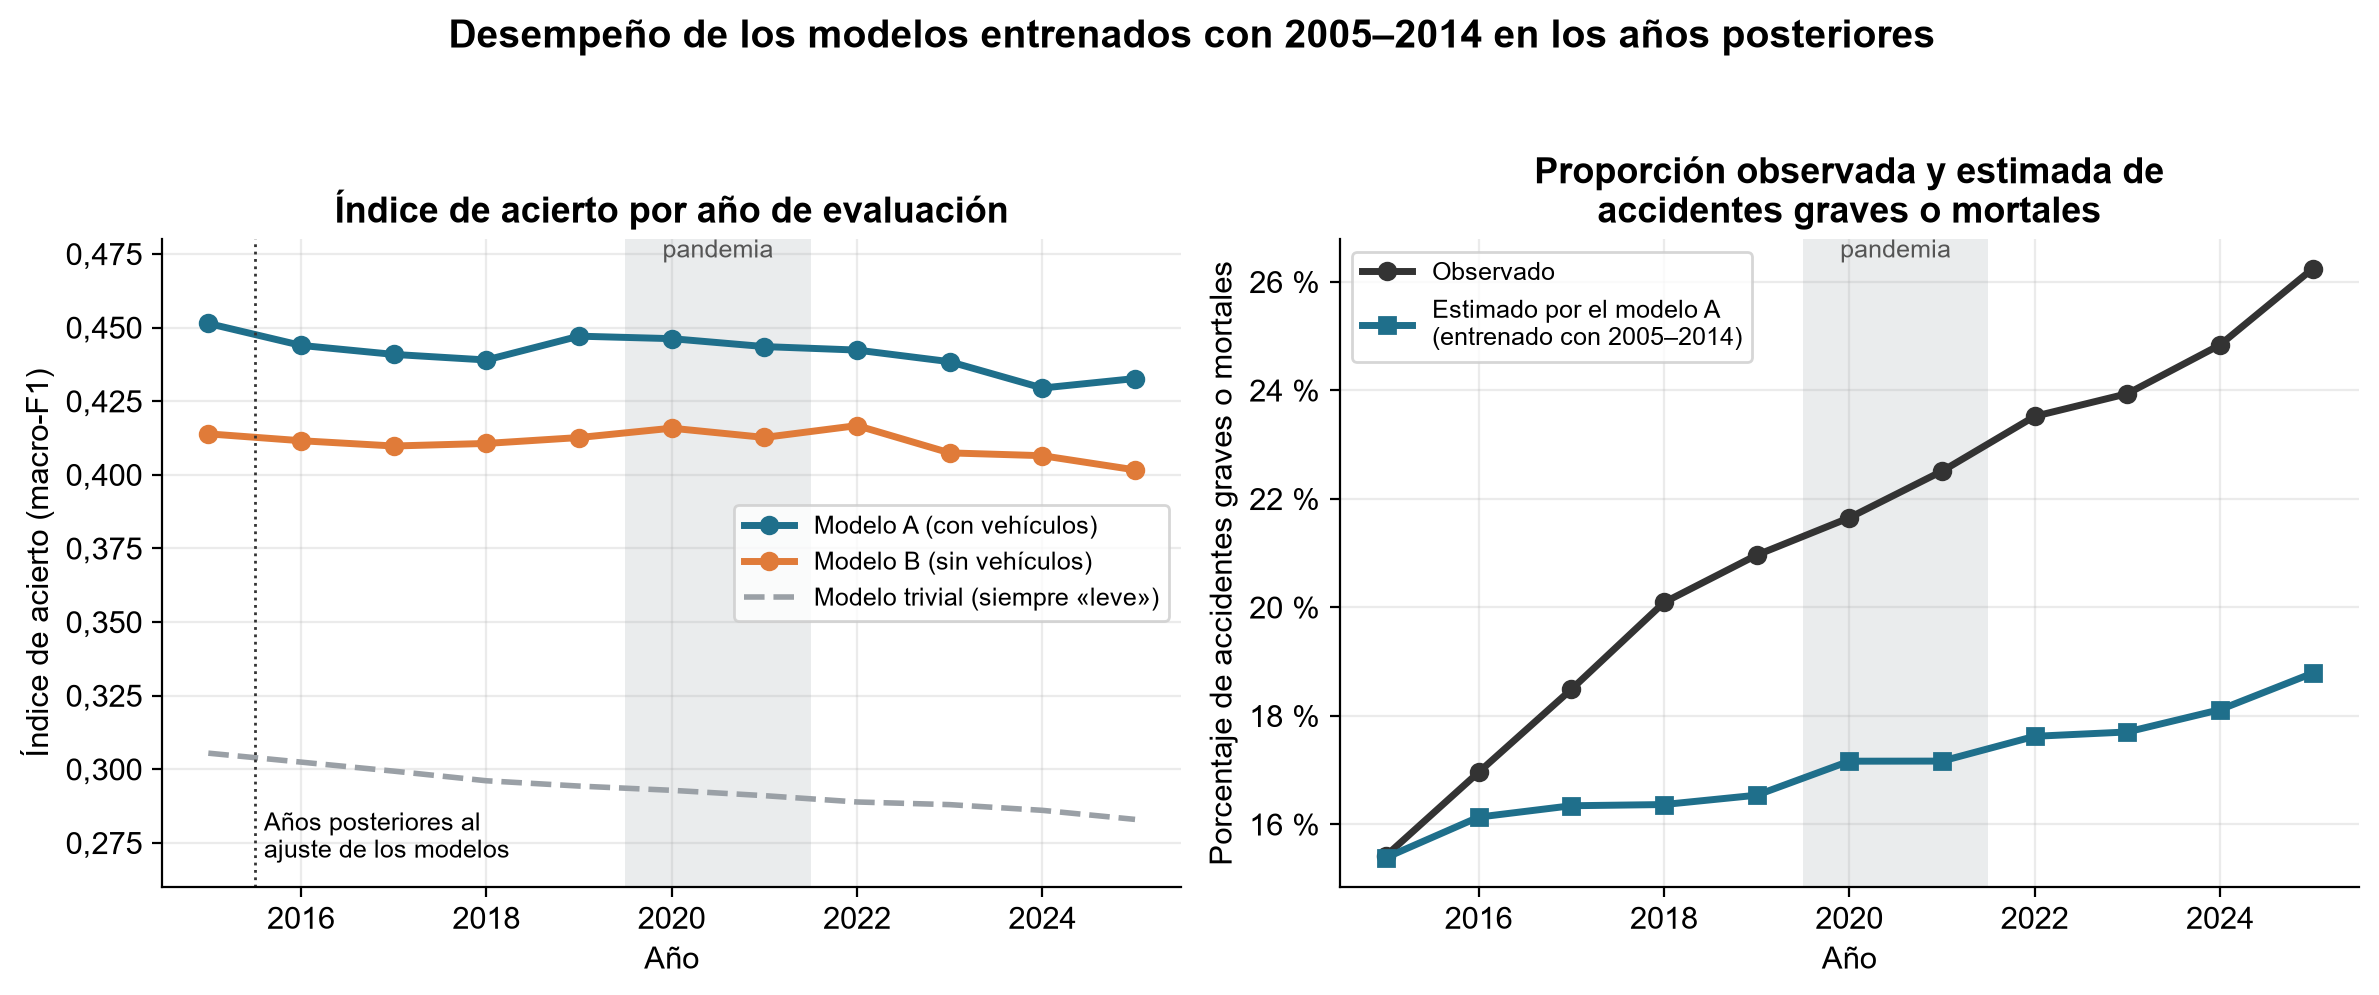

In [21]:
fc.f4_anual(a)
mostrar("F4_rendimiento_anual.png", 1000)

*Figura 10. Evolución del macro-F1 por año de evaluación y comparación entre la proporción observada y la estimada de accidentes graves o mortales. Fuente: elaboración propia con datos del DfT.*

El desempeño de los modelos disminuye gradualmente a lo largo de los años y no se observa una discontinuidad en 2020–2021; en todos los casos permanece por encima del modelo trivial. En cambio, la
proporción observada de accidentes graves o mortales crece más de lo que estiman los modelos, lo que se atribuye al cambio de sistema de registro y a otros factores. Esta desviación del nivel
se corrige mediante la recalibración (apartado 5.6).

### 5.4 Clasificación por tipo de accidente

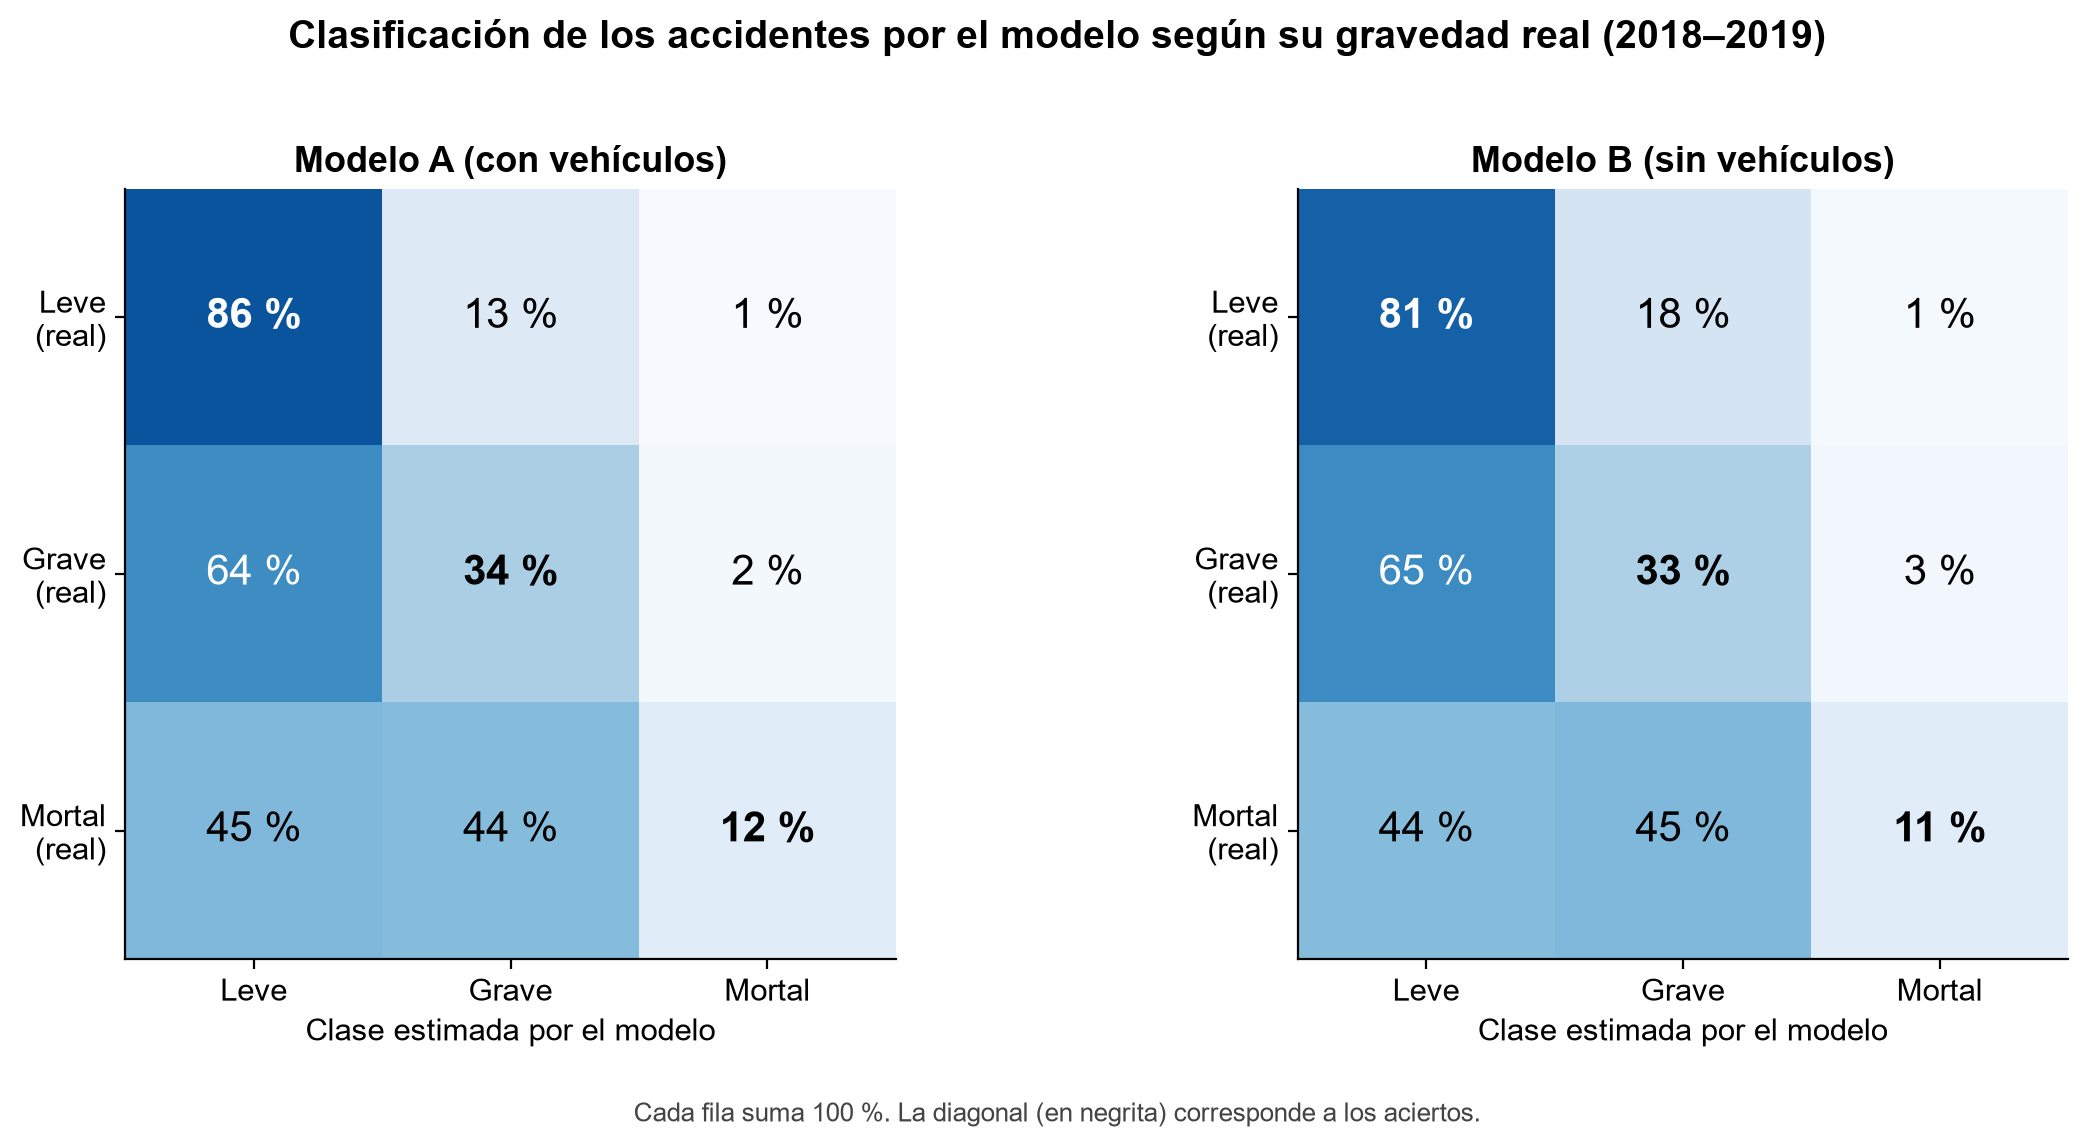

In [22]:
fc.f12_confusion(models, ev)
mostrar("F12_aciertos_por_tipo.png", 950)

*Figura 11. Matriz de confusión normalizada por fila de las versiones A y B, 2018–2019. Fuente: elaboración propia con datos del DfT.*

Los accidentes leves se clasifican correctamente con mayor frecuencia. Los mortales se confunden con frecuencia con las categorías leve y grave, lo que limita el uso de la clase más probable como
criterio para identificarlos y motiva el empleo del modo de alerta.

### 5.5 Modo de alerta para accidentes mortales

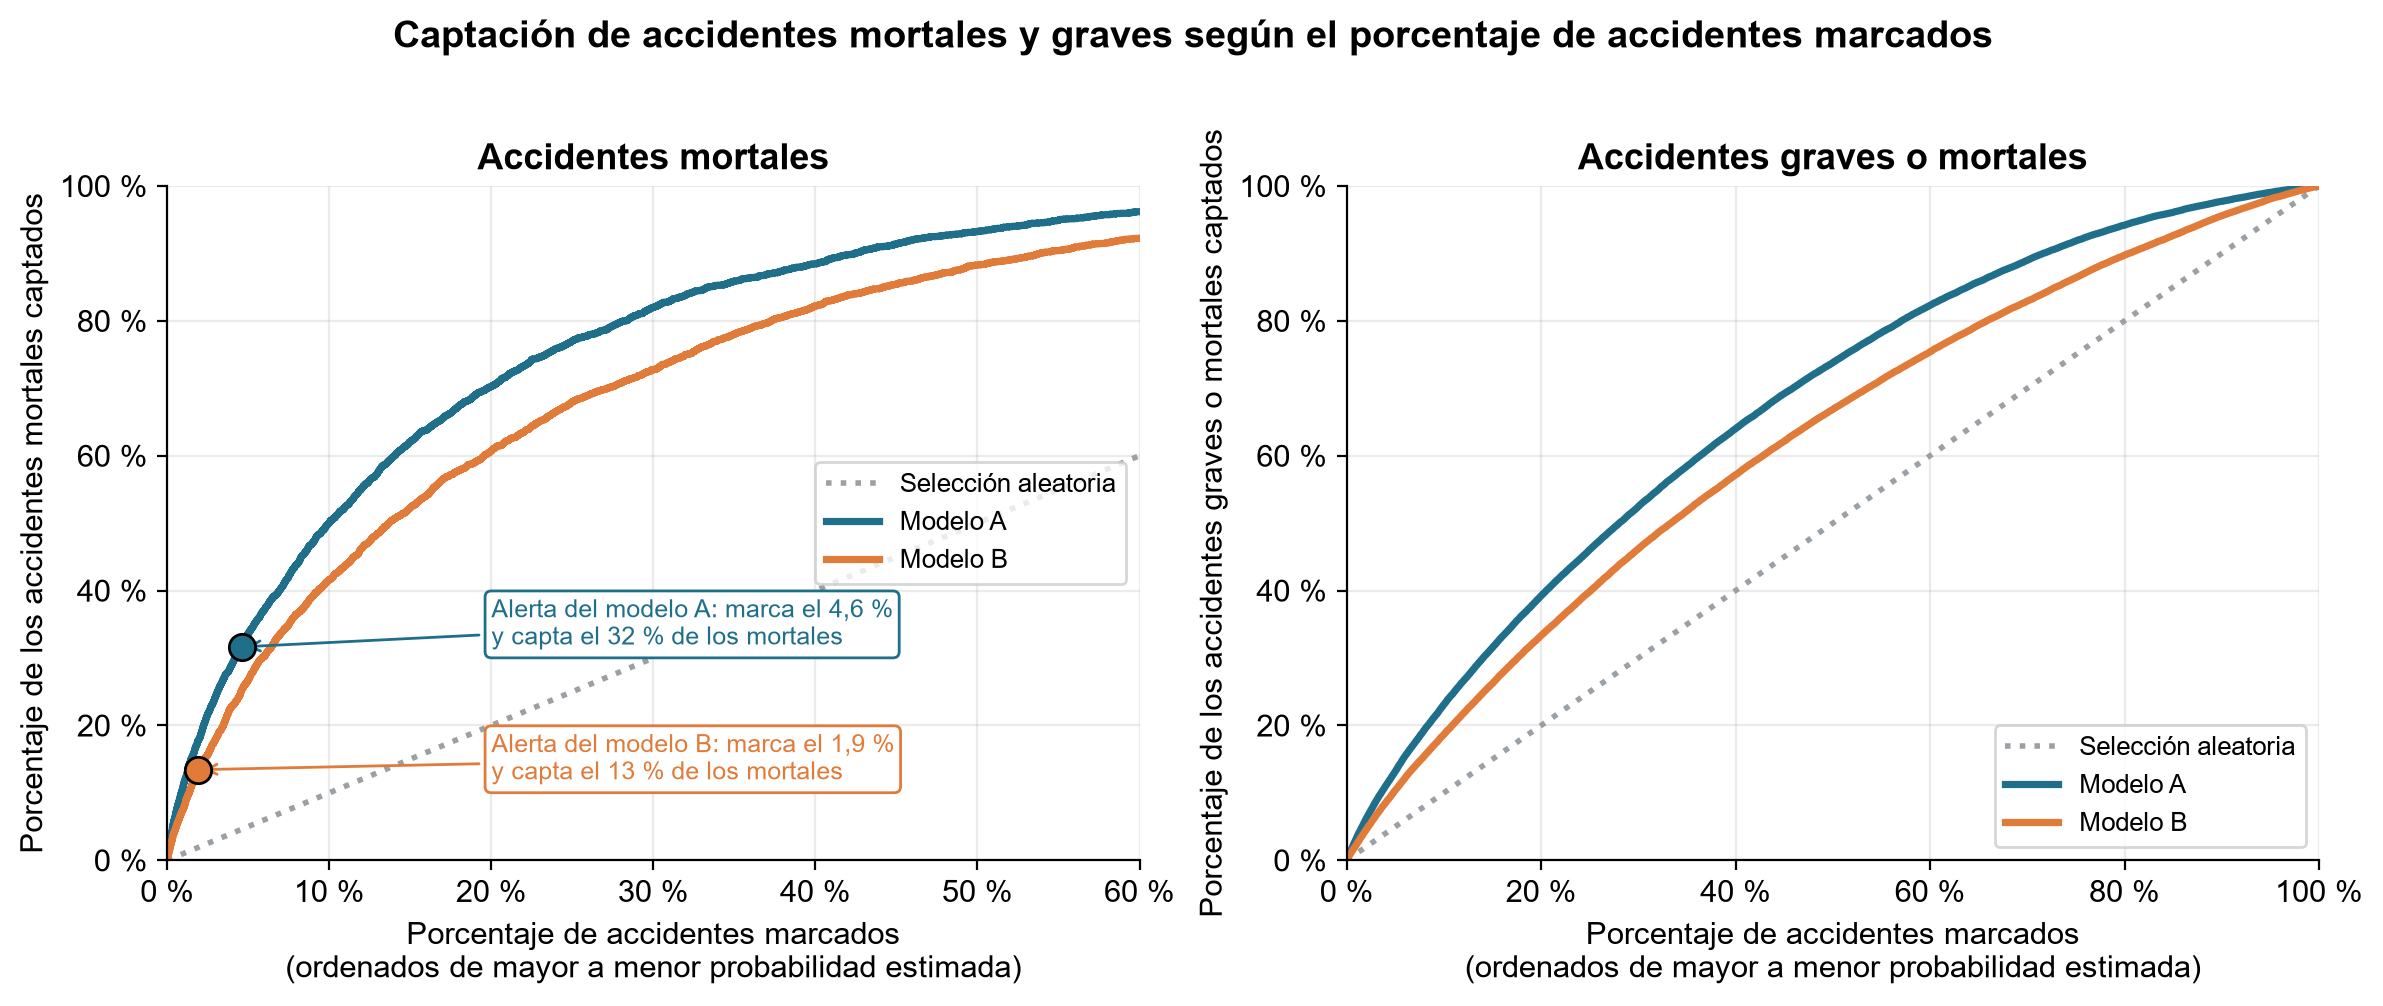

In [23]:
fc.f3_capturas(models, ev)
mostrar("F3_capturas.png", 1000)

*Figura 12. Porcentaje acumulado de accidentes mortales (izquierda) y graves o mortales (derecha) captados según el porcentaje de accidentes marcados, ordenados por la probabilidad estimada. Fuente: elaboración propia con datos del DfT.*

La ordenación de los accidentes por probabilidad estimada supera claramente a la selección aleatoria (línea punteada), aunque dista de ser perfecta. El modelo se plantea, por tanto, como un
apoyo al análisis exploratorio y no como un mecanismo de decisión automática.

### 5.6 Calibración de las probabilidades

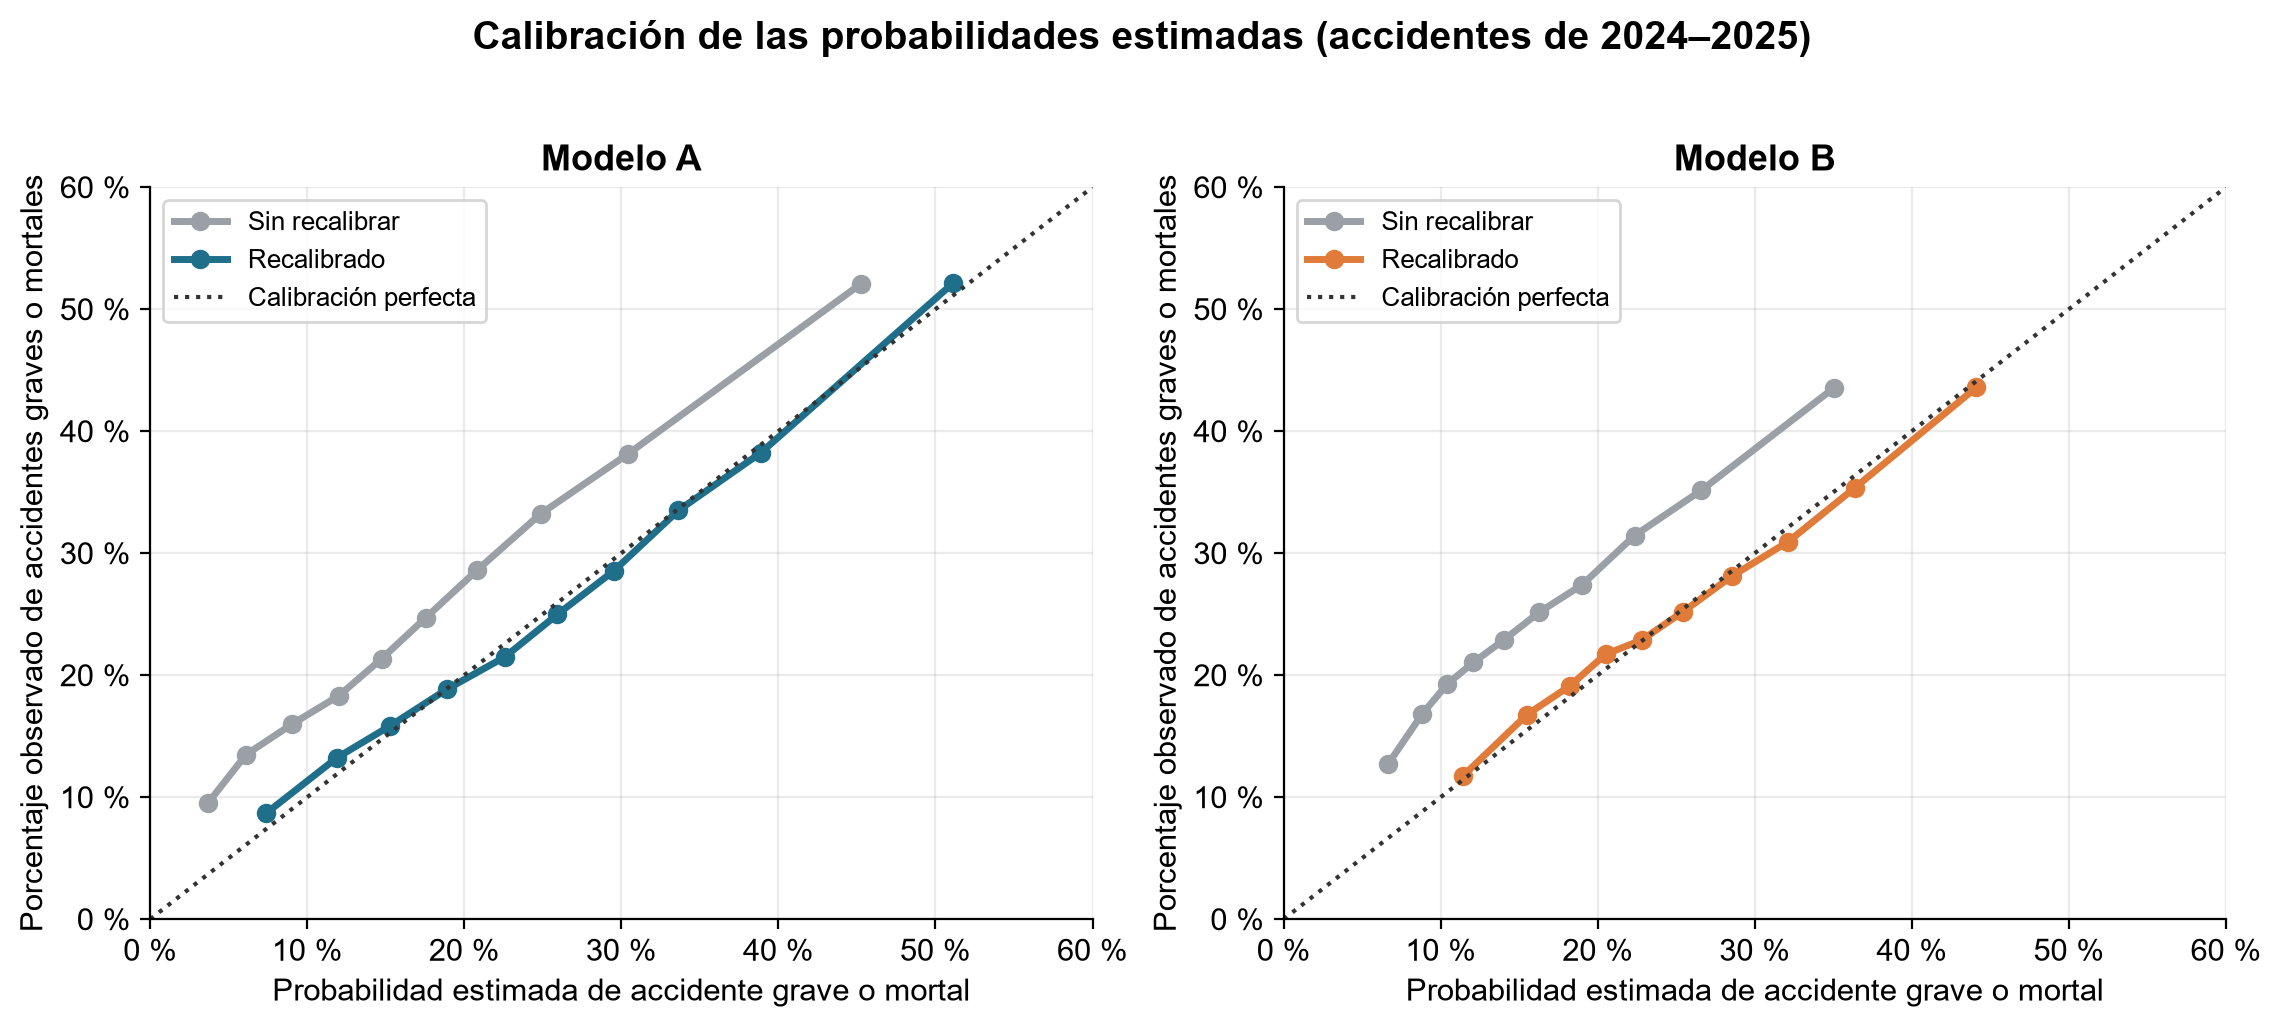

In [24]:
allv = pd.concat([d["test"], d["holdout"], d["estres"], d["post"]], ignore_index=True)
models_all = {n: (b["model"].predict_proba(allv[b["columns"]]), b, c) for n, b, c in (("A", A, fc.BLUE), ("B", B, fc.ORANGE))}
fc.f5_calibracion(models_all, allv)
mostrar("F5_calibracion.png", 950)

*Figura 13. Curvas de calibración de la probabilidad estimada de accidente grave o mortal, con y sin recalibración, 2024–2025. Fuente: elaboración propia con datos del DfT.*

*Tabla 10. Métricas de calibración según el esquema de recalibración aplicado.*

In [25]:
rc = pd.read_csv(REPORTS / "recalibracion.csv")
display(rc[["modelo", "esquema", "evaluado_en", "pred_ksi", "obs_ksi", "ece_ksi", "brier", "logloss"]].round(4))

,modelo,esquema,evaluado_en,pred_ksi,obs_ksi,ece_ksi,brier,logloss
0,A,Sin recalibrar,2024–2025,0.1845,0.2554,0.0709,0.3685,0.5982
1,A,Factores globales de 2016–17 (desfasados),2024–2025,0.2007,0.2554,0.0547,0.3647,0.5909
2,A,Factores globales de 2022–23,2024–2025,0.2472,0.2554,0.0187,0.3602,0.5812
3,A,"Factores por clase y por sistema de registro, ...",2024–2025,0.2545,0.2554,0.0222,0.3600,0.5800
4,A,"Pendiente y sesgo por sistema de registro, 202...",2024–2025,0.2551,0.2554,0.0083,0.3583,0.5770
5,B,Sin recalibrar,2024–2025,0.1712,0.2554,0.0842,0.3871,0.6249
6,B,Factores globales de 2016–17 (desfasados),2024–2025,0.1935,0.2554,0.0619,0.3809,0.6132
7,B,Factores globales de 2022–23,2024–2025,0.2478,0.2554,0.0203,0.3745,0.6012
8,B,"Factores por clase y por sistema de registro, ...",2024–2025,0.2540,0.2554,0.0220,0.3743,0.6005
9,B,"Pendiente y sesgo por sistema de registro, 202...",2024–2025,0.2542,0.2554,0.0079,0.3730,0.5988


Sin recalibración, los modelos subestiman la probabilidad de accidente grave o mortal en todos los niveles. La recalibración mediante pendiente y sesgo, diferenciada por sistema de registro, se ajusta
con los años 2022–2023 y se verifica con 2024–2025, periodo en el que las probabilidades estimadas se aproximan a las frecuencias observadas.

### 5.7 Análisis por subgrupos

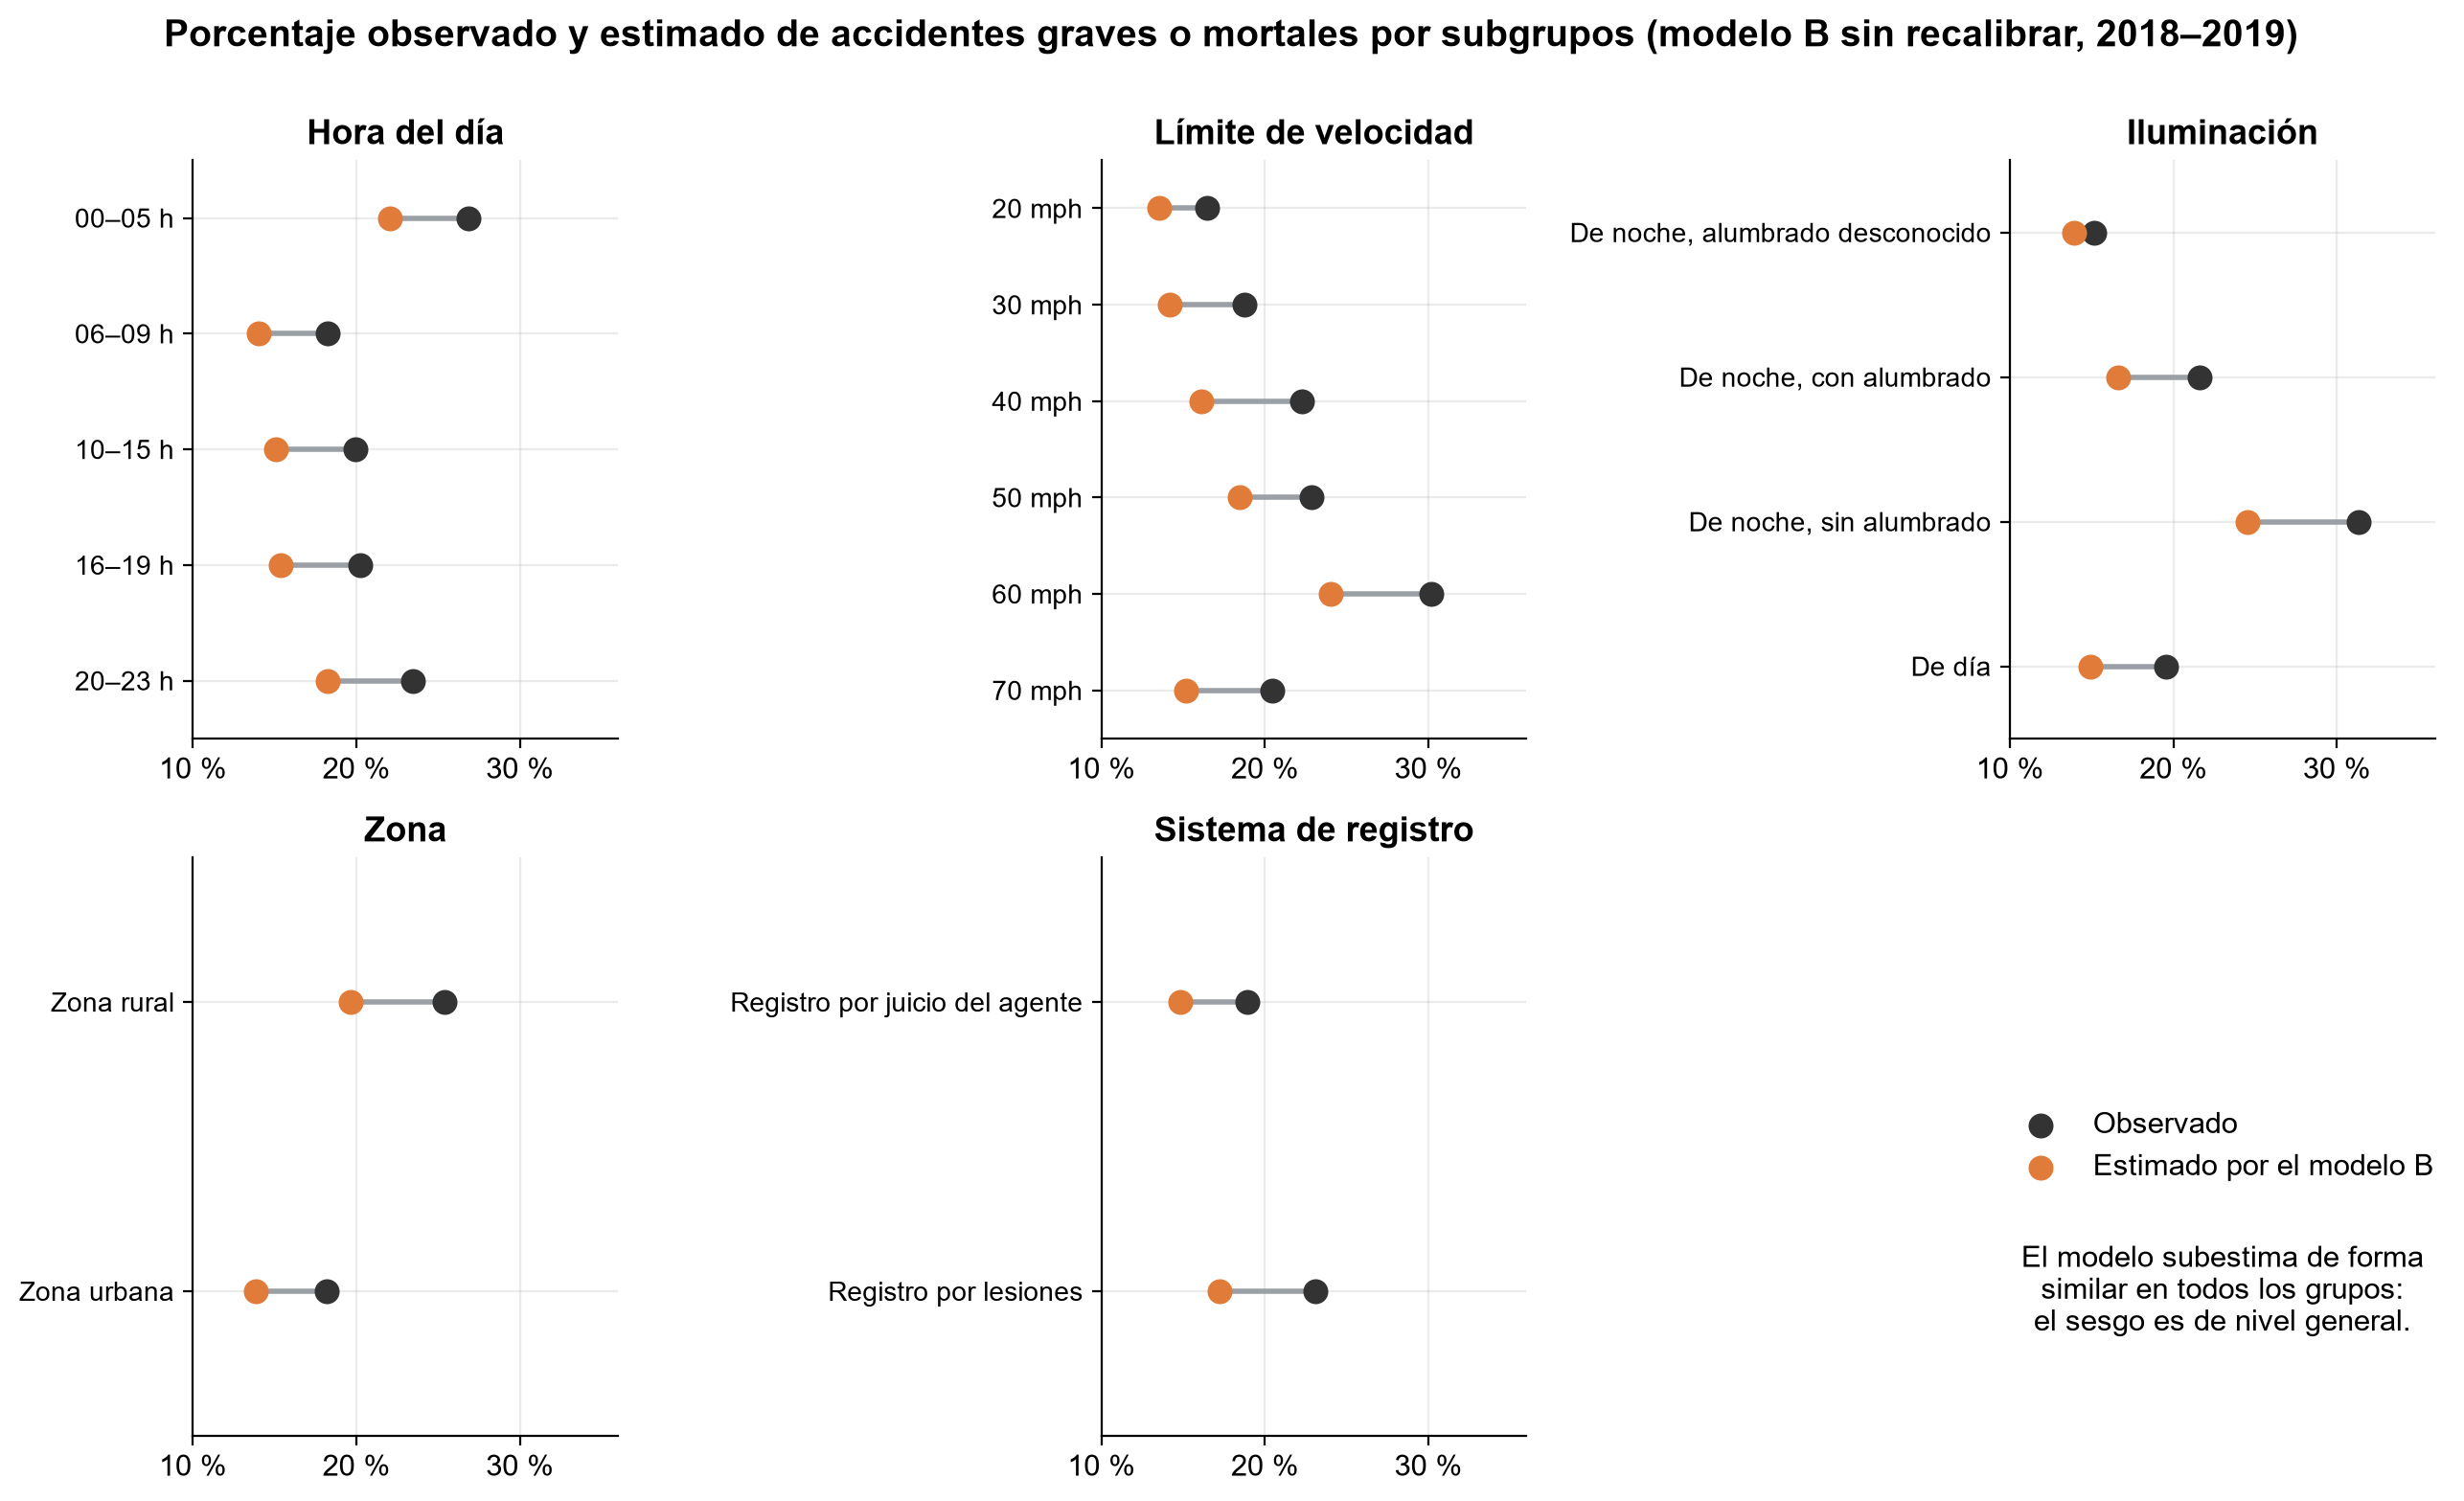

In [26]:
fc.f7_subgrupos()
mostrar("F7_subgrupos.png", 1000)

*Figura 14. Porcentaje observado y estimado por la versión B (sin recalibrar) de accidentes graves o mortales, según subgrupos, 2018–2019. Fuente: elaboración propia con datos del DfT.*

El modelo sin recalibrar subestima la proporción de accidentes graves o mortales de forma similar en todos los subgrupos. El sesgo es, por lo tanto, de nivel general y no se concentra en una categoría concreta.

### 5.8 Aporte de la ubicación y evaluación en zonas no vistas
Se compara el desempeño del modelo con y sin variables geográficas, tanto en periodos posteriores como en bloques geográficos reservados (20 % de las zonas, excluidas del entrenamiento).

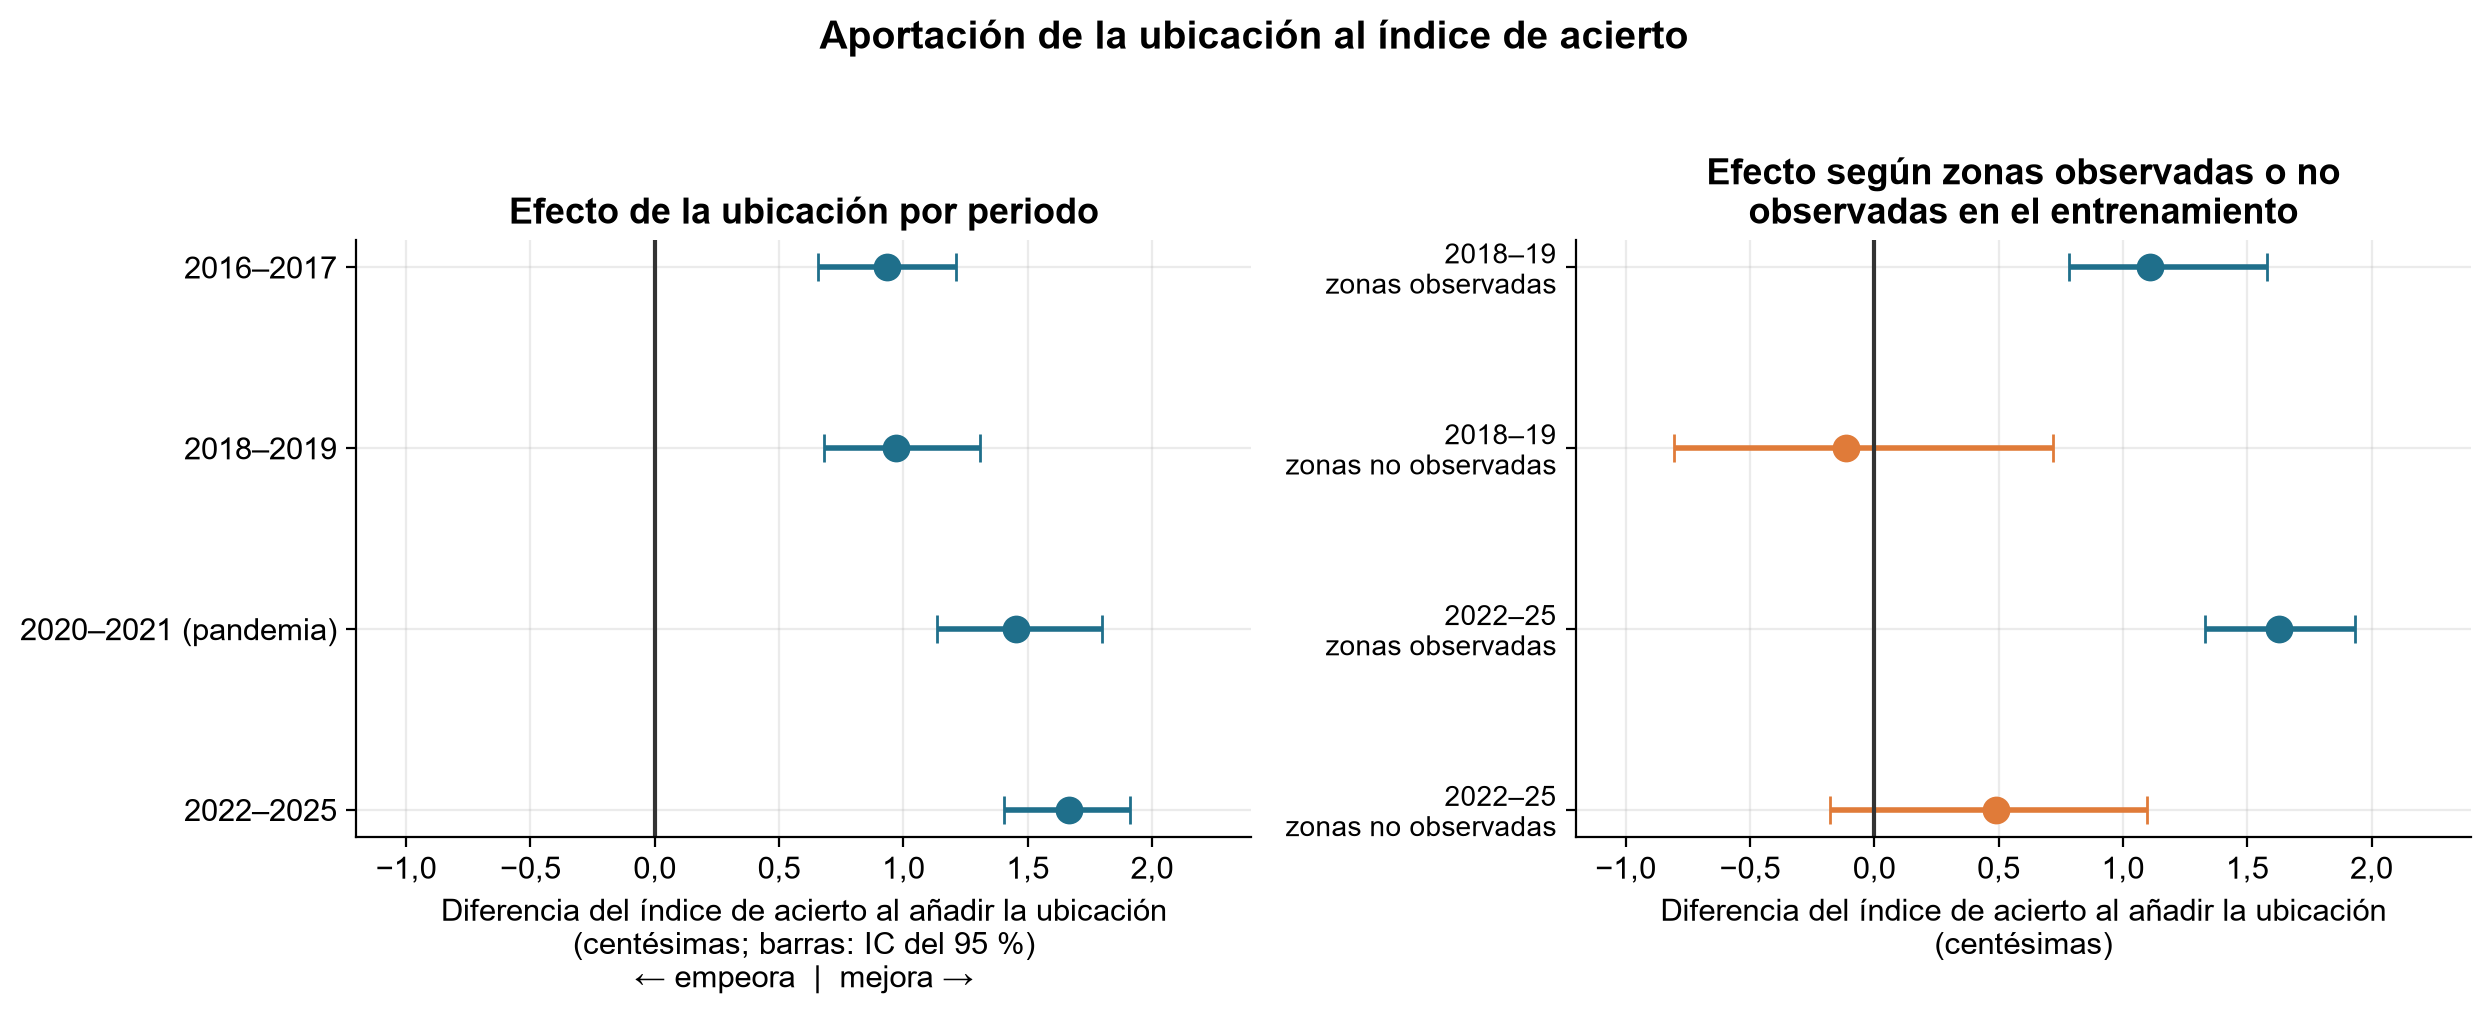

In [27]:
fc.f10_geografia()
mostrar("F10_utilidad_ubicacion.png", 1000)

*Figura 15. Diferencia de macro-F1 al incorporar la ubicación, por periodo (izquierda) y según se trate de zonas ya observadas o no observadas en el entrenamiento (derecha), con intervalo de confianza del 95 %. Fuente: elaboración propia con datos del DfT.*

*Tabla 11. Resultados de la comparación con y sin variables geográficas (muestra de filas).*

In [28]:
display(pd.read_csv(REPORTS / "holdout_ablacion.csv").round(4).head(12))

,variante,conjunto,n_vars,macro_f1,ap_ksi,ap_fatal,recall_fatal
0,A completo,test 2016-17,37,0.4425,0.3652,0.0809,0.1222
1,A completo,holdout 2018-19,37,0.4430,0.3939,0.0855,0.1151
2,A completo,estres 2020-21,37,0.4449,0.4151,0.0957,0.1016
3,A completo,post 2022-25,37,0.4362,0.4277,0.0817,0.0808
4,A sin geografía,test 2016-17,31,0.4332,0.3541,0.0775,0.1118
5,A sin geografía,holdout 2018-19,31,0.4334,0.3855,0.0814,0.1067
6,A sin geografía,estres 2020-21,31,0.4304,0.4023,0.0870,0.0838
7,A sin geografía,post 2022-25,31,0.4195,0.4173,0.0724,0.0582
8,A sin Injury_Based,test 2016-17,36,0.4425,0.3645,0.0811,0.1528
9,A sin Injury_Based,holdout 2018-19,36,0.4401,0.3905,0.0855,0.1535


La incorporación de la ubicación mejora ligeramente el desempeño, pero solo en zonas con historial previo; en zonas no observadas la diferencia no se distingue de cero. La información geográfica resulta útil,
por tanto, para interpolar entre zonas conocidas y no para extrapolar a zonas nuevas.

### 5.9 Estrategias de actualización: recalibrar o reentrenar
El desajuste descrito en los apartados 5.3 y 5.6 plantea una cuestión práctica: cuando el modelo envejece, ¿basta con recalibrarlo o conviene reentrenarlo con datos más recientes?
Para responderla se comparan tres estrategias, todas validadas con 2023 y evaluadas con los mismos años finales (2024–2025):

- **S0 (actual):** modelo entrenado con 2005–2014, sin reentrenar.
- **S1 (ventana reciente):** modelo entrenado con 2016–2022, periodo en el que el registro por lesiones ya está extendido.
- **S2 (histórico completo):** modelo entrenado con 2005–2022.

Cada estrategia se evalúa sin recalibrar y recalibrada (pendiente y sesgo por sistema de registro, ajustados únicamente con 2023). Las variables geográficas aprendidas se recalculan con los años de
entrenamiento de cada estrategia. El procedimiento se encuentra en `src/estrategias_entrenamiento.py`.

*Tabla 12. Resultados de las tres estrategias en 2024–2025, por versión del modelo (AP: precisión promedio; el macro-F1 se informa solo para las probabilidades sin recalibrar).*

In [29]:
estr = pd.read_csv(REPORTS / "estrategias_entrenamiento.csv")
estr["macro-F1"] = np.where(estr["esquema"] == "Sin recalibrar", estr["macro_f1"], np.nan)
cols_t = {"estrategia": "estrategia", "esquema": "probabilidades", "n_entrenamiento": "accidentes de entrenamiento", "macro-F1": "macro-F1",
          "ap_ksi": "AP graves+mortales", "ap_mortal": "AP mortales", "pred_ksi": "% estimado", "obs_ksi": "% observado", "ece": "error de calibración", "brier": "Brier"}
for v in ("A", "B"):
    t_v = estr[estr["version"] == v][list(cols_t)].rename(columns=cols_t).copy()
    t_v["% estimado"] = (t_v["% estimado"] * 100).round(1); t_v["% observado"] = (t_v["% observado"] * 100).round(1)
    print(f"Versión {v} ({'con' if v == 'A' else 'sin'} datos de vehículos)")
    display(t_v.round(4).fillna("—").reset_index(drop=True))

Versión A (con datos de vehículos)


,estrategia,probabilidades,accidentes de entrenamiento,macro-F1,AP graves+mortales,AP mortales,% estimado,% observado,error de calibración,Brier
0,S0 · Actual (2005–2014),Sin recalibrar,1640486,0.4414,0.4290,0.0814,18.5,25.5,0.0709,0.3685
1,S0 · Actual (2005–2014),Recalibrada con 2023,1640486,—,0.4302,0.0827,25.6,25.5,0.0084,0.3583
2,S1 · Ventana reciente (2016–2022),Sin recalibrar,804902,0.4484,0.4436,0.0827,23.2,25.5,0.0237,0.3547
3,S1 · Ventana reciente (2016–2022),Recalibrada con 2023,804902,—,0.4436,0.0826,25.6,25.5,0.0041,0.3536
4,S2 · Histórico completo (2005–2022),Sin recalibrar,2585417,0.4512,0.4445,0.0881,22.9,25.5,0.0266,0.3550
5,S2 · Histórico completo (2005–2022),Recalibrada con 2023,2585417,—,0.4446,0.0877,25.8,25.5,0.0049,0.3536


Versión B (sin datos de vehículos)


,estrategia,probabilidades,accidentes de entrenamiento,macro-F1,AP graves+mortales,AP mortales,% estimado,% observado,error de calibración,Brier
0,S0 · Actual (2005–2014),Sin recalibrar,1640486,0.4081,0.3647,0.0567,17.1,25.5,0.0842,0.3871
1,S0 · Actual (2005–2014),Recalibrada con 2023,1640486,—,0.3659,0.0575,25.7,25.5,0.0079,0.3730
2,S1 · Ventana reciente (2016–2022),Sin recalibrar,804902,0.414,0.3823,0.0601,22.6,25.5,0.0297,0.3706
3,S1 · Ventana reciente (2016–2022),Recalibrada con 2023,804902,—,0.3824,0.0602,25.3,25.5,0.0069,0.3688
4,S2 · Histórico completo (2005–2022),Sin recalibrar,2585417,0.4148,0.3818,0.0621,22.2,25.5,0.0336,0.3713
5,S2 · Histórico completo (2005–2022),Recalibrada con 2023,2585417,—,0.3820,0.0622,25.5,25.5,0.0068,0.3690


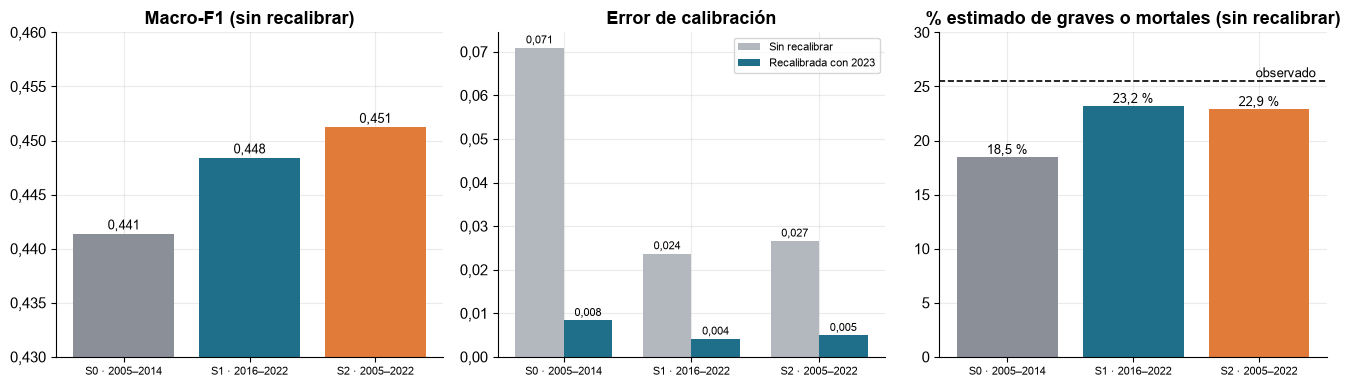

In [30]:
cols_s = {"S0": "#8a8f98", "S1": "#1f6f8b", "S2": "#e07b39"}
nombres_s = {"S0": "S0 · 2005–2014", "S1": "S1 · 2016–2022", "S2": "S2 · 2005–2022"}
va_ = estr[estr["version"] == "A"].copy(); va_["s"] = va_["estrategia"].str[:2]
raw_ = va_[va_["esquema"] == "Sin recalibrar"].set_index("s"); rec_ = va_[va_["esquema"] != "Sin recalibrar"].set_index("s")
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4))
ax = axes[0]
ax.bar([nombres_s[k] for k in raw_.index], raw_["macro_f1"], color=[cols_s[k] for k in raw_.index]); ax.set_ylim(0.43, 0.46)
for i, v in enumerate(raw_["macro_f1"]): ax.text(i, v + 0.0004, f"{v:.3f}".replace(".", ","), ha="center", fontsize=9)
ax.set_title("Macro-F1 (sin recalibrar)"); ax.tick_params(axis="x", labelsize=8)
ax = axes[1]; w_ = 0.38; x_ = np.arange(3)
ax.bar(x_ - w_/2, raw_["ece"], w_, color="#b3b8bf", label="Sin recalibrar"); ax.bar(x_ + w_/2, rec_["ece"], w_, color="#1f6f8b", label="Recalibrada con 2023")
ax.set_xticks(x_); ax.set_xticklabels([nombres_s[k] for k in raw_.index], fontsize=8); ax.set_title("Error de calibración"); ax.legend(fontsize=8)
for i, (a1, a2) in enumerate(zip(raw_["ece"], rec_["ece"])):
    ax.text(i - w_/2, a1 + 0.001, f"{a1:.3f}".replace(".", ","), ha="center", fontsize=8); ax.text(i + w_/2, a2 + 0.001, f"{a2:.3f}".replace(".", ","), ha="center", fontsize=8)
ax = axes[2]
ax.bar([nombres_s[k] for k in raw_.index], raw_["pred_ksi"] * 100, color=[cols_s[k] for k in raw_.index])
ax.axhline(raw_["obs_ksi"].iloc[0] * 100, color="k", ls="--", lw=1.2); ax.text(2.45, raw_["obs_ksi"].iloc[0] * 100 + .3, "observado", ha="right", fontsize=9)
for i, v in enumerate(raw_["pred_ksi"] * 100): ax.text(i, v + 0.3, f"{v:.1f} %".replace(".", ","), ha="center", fontsize=9)
ax.set_ylim(0, 30); ax.set_title("% estimado de graves o mortales (sin recalibrar)"); ax.tick_params(axis="x", labelsize=8)
plt.tight_layout(); plt.show()

*Figura 16. Comparación de las estrategias S0, S1 y S2 en 2024–2025 (versión A): macro-F1, error de calibración y proporción estimada de accidentes graves o mortales frente a la observada. El eje del macro-F1 no comienza en cero. Fuente: elaboración propia con datos del DfT.*

*Tabla 13. Diferencia de cada estrategia respecto de S0, con intervalo de confianza del 95 % (remuestreo pareado de los accidentes de prueba).*

In [31]:
contr = pd.read_csv(REPORTS / "estrategias_contrastes.csv")
contr["contraste"] = contr["contraste"].str.replace("\u2212", "-", regex=False)
contr["metrica"] = contr["metrica"].map({"macro_f1": "macro-F1", "ap_ksi": "AP graves+mortales", "ap_mortal": "AP mortales"})
display(contr.rename(columns={"dif_media": "diferencia", "ic95_inf": "IC95 inf", "ic95_sup": "IC95 sup"}).round(4))

,version,contraste,metrica,diferencia,IC95 inf,IC95 sup
0,A,S1 - S0,macro-F1,0.0071,0.0036,0.0107
1,A,S1 - S0,AP graves+mortales,0.0145,0.0127,0.0163
2,A,S1 - S0,AP mortales,0.0009,-0.0039,0.0052
3,A,S2 - S0,macro-F1,0.0100,0.0067,0.0130
4,A,S2 - S0,AP graves+mortales,0.0155,0.0139,0.0168
5,A,S2 - S0,AP mortales,0.0068,0.0033,0.0102
6,B,S1 - S0,macro-F1,0.0057,0.0025,0.0089
7,B,S1 - S0,AP graves+mortales,0.0178,0.0159,0.0195
8,B,S1 - S0,AP mortales,0.0031,-0.0008,0.0059
9,B,S2 - S0,macro-F1,0.0066,0.0039,0.0095


In [32]:
def es(x, nd=1):
    return f"{x:.{nd}f}".replace(".", ",")
cA = contr[contr["version"] == "A"].set_index(["contraste", "metrica"])
estr["s"] = estr["estrategia"].str[:2]
a_raw = estr[(estr["version"] == "A") & (estr["esquema"] == "Sin recalibrar")].set_index("s")
a_rec = estr[(estr["version"] == "A") & (estr["esquema"] != "Sin recalibrar")].set_index("s")
dif59 = lambda c, m, col: cA.loc[(c, m), col]
display(Markdown(f'''
**Capacidad de ordenar los casos**
- Reentrenar mejora el orden de los accidentes graves o mortales: la precisión promedio sube {es(dif59('S1 - S0', 'AP graves+mortales', 'dif_media'), 3)} con la ventana reciente y {es(dif59('S2 - S0', 'AP graves+mortales', 'dif_media'), 3)} con el histórico. Los intervalos excluyen el cero.
- El índice de acierto sube {es(dif59('S1 - S0', 'macro-F1', 'dif_media'), 3)} y {es(dif59('S2 - S0', 'macro-F1', 'dif_media'), 3)}, respectivamente.
- Para los mortales, solo mejora el histórico completo ({es(dif59('S2 - S0', 'AP mortales', 'dif_media'), 3)}; IC95 {es(dif59('S2 - S0', 'AP mortales', 'ic95_inf'), 3)} a {es(dif59('S2 - S0', 'AP mortales', 'ic95_sup'), 3)}). Con la ventana reciente no se distingue de cero.

**Nivel de los porcentajes (2024–2025)**
- Real: {es(a_raw.loc['S0', 'obs_ksi'] * 100)} %. Estimado sin ajustar: {es(a_raw.loc['S0', 'pred_ksi'] * 100)} % (S0), {es(a_raw.loc['S1', 'pred_ksi'] * 100)} % (S1) y {es(a_raw.loc['S2', 'pred_ksi'] * 100)} % (S2).
- Reentrenar reduce la diferencia de {es((a_raw.loc['S0', 'obs_ksi'] - a_raw.loc['S0', 'pred_ksi']) * 100)} a {es((a_raw.loc['S1', 'obs_ksi'] - a_raw.loc['S1', 'pred_ksi']) * 100)} y {es((a_raw.loc['S2', 'obs_ksi'] - a_raw.loc['S2', 'pred_ksi']) * 100)} puntos, pero no la elimina.

**Ajustar los porcentajes (recalibrar)**
- El error queda en {es(a_rec.loc['S0', 'ece'], 3)} (S0), {es(a_rec.loc['S1', 'ece'], 3)} (S1) y {es(a_rec.loc['S2', 'ece'], 3)} (S2). El índice de Brier pasa de {es(a_rec.loc['S0', 'brier'], 4)} a {es(a_rec.loc['S1', 'brier'], 4)} y {es(a_rec.loc['S2', 'brier'], 4)}.

**Lectura**
- Ajustar los porcentajes es lo que más corrige el nivel (el error de S0 baja de {es(a_raw.loc['S0', 'ece'], 3)} a {es(a_rec.loc['S0', 'ece'], 3)}). Reentrenar mejora sobre todo el orden de los casos.
- Hacer las dos cosas da los mejores resultados.
- S1 y S2 se parecen. S2 es la única que mejora los mortales, pero entrena con 2,6 millones de registros frente a 0,8.
- La diferencia que queda es coherente con que la proporción real siguió subiendo en 2024–2025; este experimento no lo prueba.
- Los intervalos solo reflejan el muestreo de los accidentes de prueba, no la variación propia del entrenamiento.
'''))


**Capacidad de ordenar los casos**
- Reentrenar mejora el orden de los accidentes graves o mortales: la precisión promedio sube 0,014 con la ventana reciente y 0,015 con el histórico. Los intervalos excluyen el cero.
- El índice de acierto sube 0,007 y 0,010, respectivamente.
- Para los mortales, solo mejora el histórico completo (0,007; IC95 0,003 a 0,010). Con la ventana reciente no se distingue de cero.

**Nivel de los porcentajes (2024–2025)**
- Real: 25,5 %. Estimado sin ajustar: 18,5 % (S0), 23,2 % (S1) y 22,9 % (S2).
- Reentrenar reduce la diferencia de 7,1 a 2,4 y 2,7 puntos, pero no la elimina.

**Ajustar los porcentajes (recalibrar)**
- El error queda en 0,008 (S0), 0,004 (S1) y 0,005 (S2). El índice de Brier pasa de 0,3583 a 0,3536 y 0,3536.

**Lectura**
- Ajustar los porcentajes es lo que más corrige el nivel (el error de S0 baja de 0,071 a 0,008). Reentrenar mejora sobre todo el orden de los casos.
- Hacer las dos cosas da los mejores resultados.
- S1 y S2 se parecen. S2 es la única que mejora los mortales, pero entrena con 2,6 millones de registros frente a 0,8.
- La diferencia que queda es coherente con que la proporción real siguió subiendo en 2024–2025; este experimento no lo prueba.
- Los intervalos solo reflejan el muestreo de los accidentes de prueba, no la variación propia del entrenamiento.


## 6. Interpretación de los modelos mediante valores SHAP
Los valores SHAP (*SHapley Additive exPlanations*) cuantifican la contribución de cada variable a las predicciones del modelo. Permiten ordenar las variables según su importancia y comprobar
que el modelo no se apoya en variables que filtran la respuesta. No informan sobre relaciones causales ni sobre el sentido del efecto de cada variable.

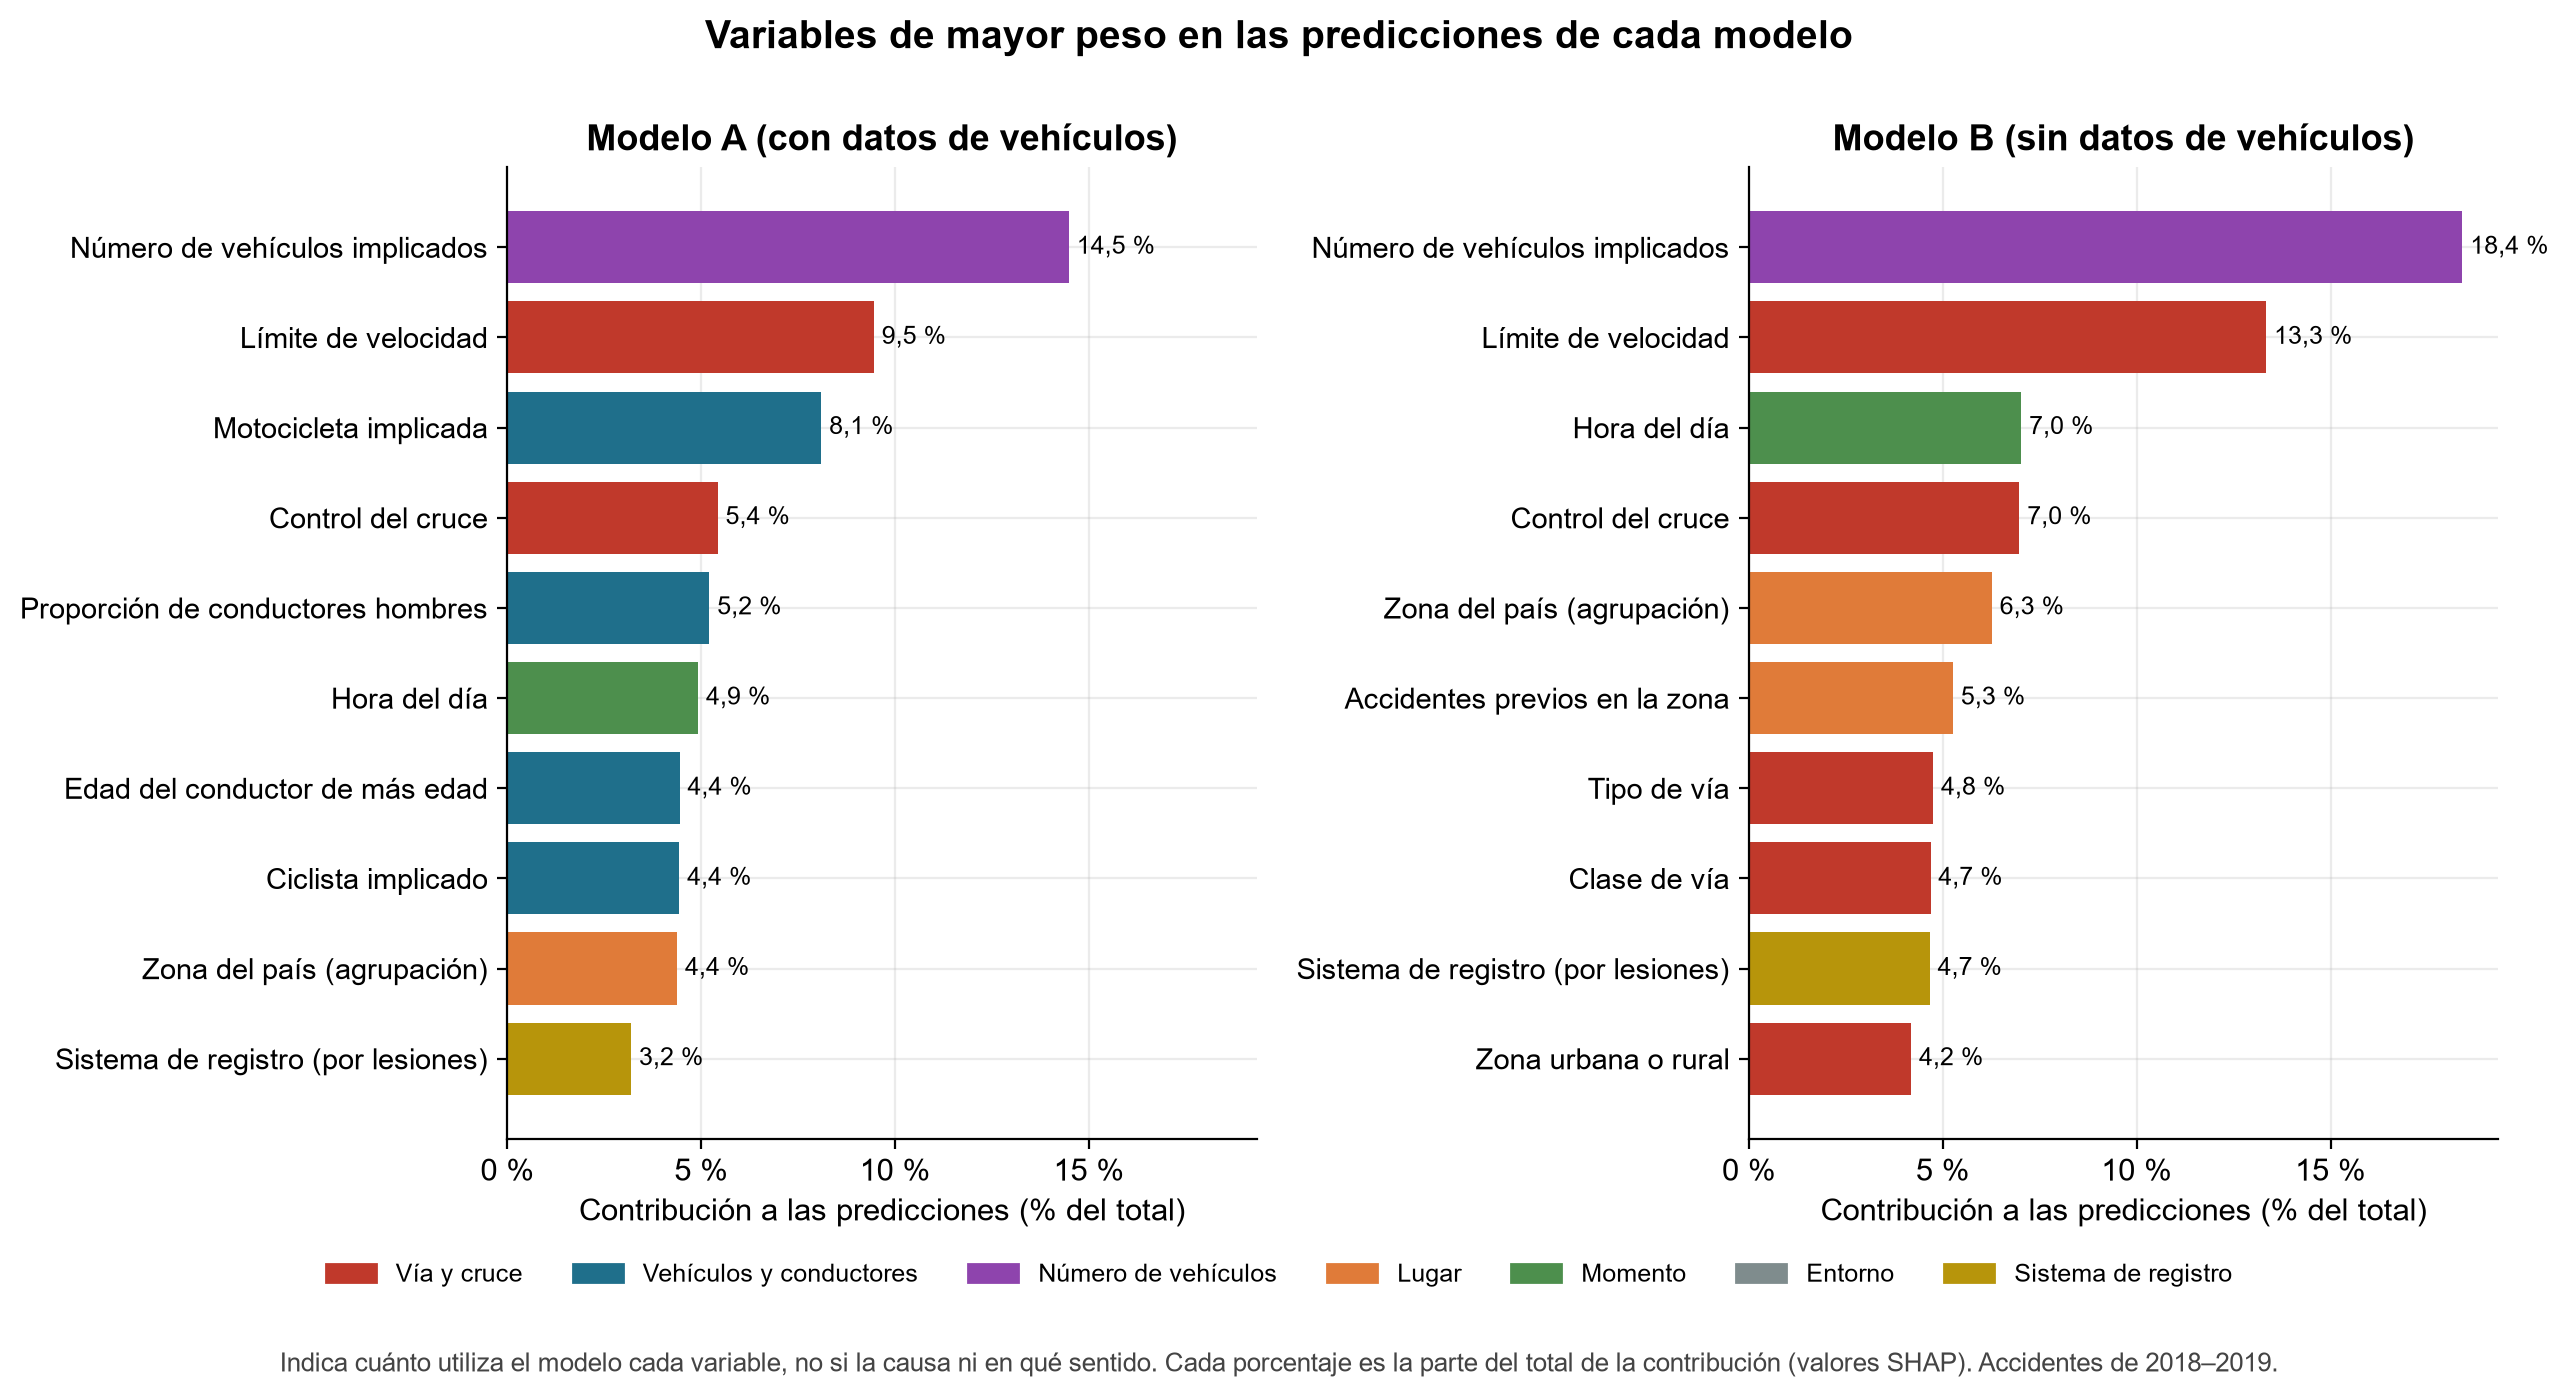

In [33]:
tops = fc.f6_factores(models, ev)
mostrar("F6_factores_principales.png", 1050)

*Figura 17. Diez variables de mayor peso en las predicciones de las versiones A y B (porcentaje del total de contribución SHAP), 2018–2019. Fuente: elaboración propia con datos del DfT.*

*Tabla 14. Peso de cada grupo de variables en las predicciones (porcentaje del total).*

In [34]:
g = pd.read_csv(REPORTS / "shap_por_grupo.csv", index_col=0)
display(g.round(1))

,A (con vehículos),B (sin vehículos)
Geografía,11.1,16.8
Tiempo,8.7,13.0
Entorno,5.7,9.4
Vía,25.9,38.3
Nº de vehículos,14.3,18.0
Sistema de registro,3.1,4.5
Vehículos y conductores,31.2,0.0


En ambas versiones, el número de vehículos implicados y el límite de velocidad ocupan los dos primeros lugares. En la versión A, las variables relativas a los vehículos y
conductores (presencia de una motocicleta o de un ciclista, edad y sexo de los conductores) ocupan posiciones destacadas, lo que indica su aporte al análisis y es coherente con la mejora de la
versión A respecto de la B.

## 7. Resultados y conclusiones
Este apartado integra los resultados de los apartados anteriores en relación con la pregunta de investigación. Las cifras provienen de los resultados
almacenados; el periodo de referencia es la evaluación principal (2018–2019), salvo indicación contraria.

### 7.1 Aporte de los datos de vehículos y conductores

In [36]:
def es(x, nd=1):                       # formato numérico con coma decimal
    return f"{x:.{nd}f}".replace(".", ",")

def mil(n):                            # separador de miles con punto
    return f"{int(n):,}".replace(",", ".")

sg = pd.read_csv(REPORTS / "shap_por_grupo.csv", index_col=0)
mt = pd.read_csv(REPORTS / "holdout_metricas.csv").set_index(["modelo", "conjunto"])
hA, hB = mt.loc[("A", "holdout 2018-19")], mt.loc[("B", "holdout 2018-19")]
yf = (y == 2).astype(int)
cap = {}
for k in ("A", "B"):
    xx, cc = fc.captura(yf, models[k][0][:, 2]); cap[k] = float(np.interp(5, xx, cc))
pA, pB = tops["A"], tops["B"]
gv = sg.loc["Vehículos y conductores", "A (con vehículos)"]; gvia_A, gvia_B = sg.loc["Vía", "A (con vehículos)"], sg.loc["Vía", "B (sin vehículos)"]
ggeo_A, ggeo_B = sg.loc["Geografía", "A (con vehículos)"], sg.loc["Geografía", "B (sin vehículos)"]
gtie_A, gtie_B = sg.loc["Tiempo", "A (con vehículos)"], sg.loc["Tiempo", "B (sin vehículos)"]
assert bool((mt.loc["A"]["macro_f1"].values > mt.loc["B"]["macro_f1"].values).all()), "A no supera a B en todos los periodos"

display(Markdown(f'''
**Cuánto mejoran los datos de vehículos y conductores**
- La versión A (con vehículos) supera a la B (sin ellos) en todos los años evaluados.
- En 2018–2019, el índice de acierto (macro-F1) es {es(hA.macro_f1, 3)} frente a {es(hB.macro_f1, 3)}.
- La capacidad de ordenar los accidentes mortales (precisión promedio) sube de {es(hB.ap_fatal, 3)} a {es(hA.ap_fatal, 3)}.
- Si se revisa primero el 5 % de accidentes con más riesgo, A capta el {es(cap['A'])} % de los mortales y B el {es(cap['B'])} %.

**Qué peso tienen dentro del modelo A**
- Los vehículos y conductores son el grupo que más pesa: {es(gv)} % del total, por delante de la vía ({es(gvia_A)} %).
- La moto es la tercera variable más importante ({es(pA['veh_motorcycle_any'])} %), después del número de vehículos ({es(pA['Number_of_Vehicles'])} %) y del límite de velocidad ({es(pA['Speed_limit'])} %).
- Siguen la proporción de conductores hombres ({es(pA['male_share'])} %), la edad del conductor mayor ({es(pA['driver_age_max'])} %) y la presencia de un ciclista ({es(pA['veh_pedalcycle_any'])} %).

**Qué pasa en el modelo B**
- No tiene datos de vehículos, así que no puede usar la moto ni al ciclista.
- Su peso se traslada a la vía (de {es(gvia_A)} % a {es(gvia_B)} %), al lugar (de {es(ggeo_A)} % a {es(ggeo_B)} %) y a la hora (de {es(gtie_A)} % a {es(gtie_B)} %).
- Aun así acierta menos: esas variables solo reemplazan en parte lo que aportan los vehículos.
'''))


**Cuánto mejoran los datos de vehículos y conductores**
- La versión A (con vehículos) supera a la B (sin ellos) en todos los años evaluados.
- En 2018–2019, el índice de acierto (macro-F1) es 0,443 frente a 0,412.
- La capacidad de ordenar los accidentes mortales (precisión promedio) sube de 0,058 a 0,086.
- Si se revisa primero el 5 % de accidentes con más riesgo, A capta el 33,7 % de los mortales y B el 26,7 %.

**Qué peso tienen dentro del modelo A**
- Los vehículos y conductores son el grupo que más pesa: 31,2 % del total, por delante de la vía (25,9 %).
- La moto es la tercera variable más importante (8,1 %), después del número de vehículos (14,5 %) y del límite de velocidad (9,5 %).
- Siguen la proporción de conductores hombres (5,2 %), la edad del conductor mayor (4,4 %) y la presencia de un ciclista (4,4 %).

**Qué pasa en el modelo B**
- No tiene datos de vehículos, así que no puede usar la moto ni al ciclista.
- Su peso se traslada a la vía (de 25,9 % a 38,3 %), al lugar (de 11,1 % a 16,8 %) y a la hora (de 8,7 % a 13,0 %).
- Aun así acierta menos: esas variables solo reemplazan en parte lo que aportan los vehículos.


### 7.2 Factores de mayor peso y su sentido descriptivo
Los valores SHAP indican cuánto utiliza el modelo cada variable, pero no el sentido de su asociación con la gravedad. Para complementarlo, la Tabla 15 presenta la proporción observada de accidentes graves o
mortales según la presencia de motocicletas o ciclistas y según el número de vehículos. Se utilizan únicamente los accidentes con información de vehículos.

*Tabla 15. Porcentaje de accidentes graves o mortales y de accidentes mortales según características de los vehículos implicados, 2018–2019.*

In [37]:
ev_v = ev[ev["has_vehicle_info"] == 1]
def fila(nombre, mask):
    s = ev_v[mask]
    return {"grupo": nombre, "accidentes": len(s), "% graves o mortales": round(s["ksi"].mean() * 100, 1), "% mortales": round((s["severity"] == 2).mean() * 100, 2)}
nv = ev_v["Number_of_Vehicles"]
tabla12 = pd.DataFrame([
    fila("Con motocicleta", ev_v["veh_motorcycle_any"] == 1), fila("Sin motocicleta", ev_v["veh_motorcycle_any"] == 0),
    fila("Con ciclista", ev_v["veh_pedalcycle_any"] == 1), fila("Sin ciclista", ev_v["veh_pedalcycle_any"] == 0),
    fila("1 vehículo", nv == 1), fila("2 vehículos", nv == 2), fila("3 o más vehículos", nv >= 3),
]).set_index("grupo")
display(tabla12)

,accidentes,% graves o mortales,% mortales
grupo,,,
Con motocicleta,34363,34.4,2.07
Sin motocicleta,205725,18.2,1.27
Con ciclista,34954,22.4,0.60
Sin ciclista,205134,20.2,1.52
1 vehículo,69986,27.8,2.09
2 vehículos,145971,17.1,0.94
3 o más vehículos,24131,20.0,2.04


*Nota. Los accidentes mortales están incluidos en la columna «% graves o mortales»; la diferencia entre ambas columnas corresponde a los accidentes graves que no fueron mortales.*

In [38]:
t12 = tabla12
display(Markdown(f'''
- **Moto.** Con moto, el {es(t12.loc['Con motocicleta', '% graves o mortales'])} % de los accidentes es grave o mortal; sin moto, el {es(t12.loc['Sin motocicleta', '% graves o mortales'])} %. Mortales: {es(t12.loc['Con motocicleta', '% mortales'], 2)} % frente a {es(t12.loc['Sin motocicleta', '% mortales'], 2)} %.
- **Ciclista.** Con ciclista hay más accidentes graves o mortales ({es(t12.loc['Con ciclista', '% graves o mortales'])} % frente a {es(t12.loc['Sin ciclista', '% graves o mortales'])} %), pero menos mortales ({es(t12.loc['Con ciclista', '% mortales'], 2)} % frente a {es(t12.loc['Sin ciclista', '% mortales'], 2)} %).
- **Número de vehículos.** Con 1 vehículo, el {es(t12.loc['1 vehículo', '% graves o mortales'])} % es grave o mortal; con 2, el {es(t12.loc['2 vehículos', '% graves o mortales'])} %; con 3 o más, el {es(t12.loc['3 o más vehículos', '% graves o mortales'])} %. No sube de forma pareja.
- **Importancia en el modelo.** El número de vehículos y el límite de velocidad son los dos factores más importantes en ambas versiones ({es(pA['Number_of_Vehicles'])} % y {es(pA['Speed_limit'])} % en A; {es(pB['Number_of_Vehicles'])} % y {es(pB['Speed_limit'])} % en B).

Son comparaciones simples: no tienen en cuenta el resto de variables y no prueban que una cosa cause la otra.
'''))


- **Moto.** Con moto, el 34,4 % de los accidentes es grave o mortal; sin moto, el 18,2 %. Mortales: 2,07 % frente a 1,27 %.
- **Ciclista.** Con ciclista hay más accidentes graves o mortales (22,4 % frente a 20,2 %), pero menos mortales (0,60 % frente a 1,52 %).
- **Número de vehículos.** Con 1 vehículo, el 27,8 % es grave o mortal; con 2, el 17,1 %; con 3 o más, el 20,0 %. No sube de forma pareja.
- **Importancia en el modelo.** El número de vehículos y el límite de velocidad son los dos factores más importantes en ambas versiones (14,5 % y 9,5 % en A; 18,4 % y 13,3 % en B).

Son comparaciones simples: no tienen en cuenta el resto de variables y no prueban que una cosa cause la otra.


### 7.3 Estabilidad temporal y calibración

In [39]:
py = pd.read_csv(REPORTS / "holdout_por_anio.csv")
g = lambda mod, yr, col: float(py[(py["modelo"] == mod) & (py["año"] == yr)][col].iloc[0])
rc = pd.read_csv(REPORTS / "recalibracion.csv")
rc_A = rc[(rc["modelo"] == "A") & (rc["evaluado_en"] == rc["evaluado_en"].iloc[0])]
sin = rc_A[rc_A["esquema"] == "Sin recalibrar"].iloc[0]; mejor = rc_A.sort_values("ece_ksi").iloc[0]
display(Markdown(f'''
- **Pierde acierto poco a poco.** El índice de acierto de A baja de {es(g('A', 2015, 'macro_f1'), 3)} (2015) a {es(g('A', 2025, 'macro_f1'), 3)} (2025); el de B, de {es(g('B', 2015, 'macro_f1'), 3)} a {es(g('B', 2025, 'macro_f1'), 3)}.
- **La pandemia no lo afecta.** En A, el acierto es {es(g('A', 2019, 'macro_f1'), 3)} en 2019 y {es(g('A', 2020, 'macro_f1'), 3)} en 2020: no hay salto.
- **Lo que sí cambia es el nivel.** La proporción real de accidentes graves o mortales pasa de {es(g('A', 2015, 'obs_ksi') * 100)} % (2015) a {es(g('A', 2025, 'obs_ksi') * 100)} % (2025); el modelo A estima {es(g('A', 2015, 'pred_ksi_raw') * 100)} % y {es(g('A', 2025, 'pred_ksi_raw') * 100)} %.
  En 2025 se queda corto por {es((g('A', 2025, 'obs_ksi') - g('A', 2025, 'pred_ksi_raw')) * 100)} puntos.
- **Ajustar los porcentajes lo corrige.** Con la recalibración, el error baja de {es(sin.ece_ksi, 3)} a {es(mejor.ece_ksi, 3)} en {sin.evaluado_en}.
'''))


- **Pierde acierto poco a poco.** El índice de acierto de A baja de 0,451 (2015) a 0,433 (2025); el de B, de 0,414 a 0,402.
- **La pandemia no lo afecta.** En A, el acierto es 0,447 en 2019 y 0,446 en 2020: no hay salto.
- **Lo que sí cambia es el nivel.** La proporción real de accidentes graves o mortales pasa de 15,4 % (2015) a 26,2 % (2025); el modelo A estima 15,4 % y 18,8 %.
  En 2025 se queda corto por 7,5 puntos.
- **Ajustar los porcentajes lo corrige.** Con la recalibración, el error baja de 0,071 a 0,008 en 2024–2025.


### 7.4 Qué accidentes mortales detecta el modelo y cuáles no

In [40]:
mdv = pd.read_csv(REPORTS / "mortales_detectados_vs_perdidos.csv", index_col=0)
cd, cn, ct = "A 2018–19 · mortales detectados", "A 2018–19 · mortales NO detectados", "A 2018–19 · todos los accidentes"
bd = "B 2018–19 · mortales detectados"
display(Markdown(f'''
- El modo de alerta de A detecta {mil(mdv.loc['n', cd])} de los {mil(mdv.loc['n', cd] + mdv.loc['n', cn])} accidentes mortales de 2018–2019.
- **Los que detecta** ocurren sobre todo fuera de la ciudad: solo el {es(mdv.loc['% urbano', cd])} % es urbano, frente al {es(mdv.loc['% urbano', cn])} % de los que se le escapan.
- Tienen más velocidad (límite medio de {es(mdv.loc['límite medio (mph)', cd])} mph frente a {es(mdv.loc['límite medio (mph)', cn])} mph) y ocurren más de madrugada ({es(mdv.loc['% madrugada (0-5 h)', cd])} % frente a {es(mdv.loc['% madrugada (0-5 h)', cn])} %).
- **En resumen:** el modelo reconoce el perfil de vía rápida, fuera de la ciudad y de noche, y falla más con los mortales urbanos, que son casi la mitad de los que no detecta.
- La precisión de la alerta es de {es(hA.alert_precision * 100, 0)} %: de cada 10 accidentes marcados, solo {es(hA.alert_precision * 10, 0)} es mortal. Sirve para priorizar la revisión, no para decidir caso por caso.
'''))


- El modo de alerta de A detecta 1.053 de los 3.328 accidentes mortales de 2018–2019.
- **Los que detecta** ocurren sobre todo fuera de la ciudad: solo el 18,0 % es urbano, frente al 48,0 % de los que se le escapan.
- Tienen más velocidad (límite medio de 55,2 mph frente a 43,3 mph) y ocurren más de madrugada (21,3 % frente a 10,8 %).
- **En resumen:** el modelo reconoce el perfil de vía rápida, fuera de la ciudad y de noche, y falla más con los mortales urbanos, que son casi la mitad de los que no detecta.
- La precisión de la alerta es de 10 %: de cada 10 accidentes marcados, solo 1 es mortal. Sirve para priorizar la revisión, no para decidir caso por caso.


### 7.5 Información geográfica, sistema de registro y algoritmos

In [41]:
hc = pd.read_csv(REPORTS / "holdout_contrastes.csv")
geo_c = hc[hc["contraste"].str.startswith("con geografía")].set_index("conjunto")
inj_c = hc[hc["contraste"].str.startswith("con Injury")].set_index("conjunto")
sc = pd.read_csv(REPORTS / "separacion_geografica_contraste.csv"); sc.columns = ["conjunto", "grupo", "dif", "inf", "sup", "n"]
nuevo = sc[sc["grupo"].str.contains("NO")].set_index("conjunto"); visto = sc[~sc["grupo"].str.contains("NO")].set_index("conjunto")
rs = pd.read_csv(REPORTS / "holdout_sistema_registro.csv")
r_ib = rs[(rs["modelo"] == "A") & (rs["conjunto"] == "post 2022-25") & rs["sistema_registro"].str.contains("lesiones")].iloc[0]
r_rp = rs[(rs["modelo"] == "A") & (rs["conjunto"] == "post 2022-25") & rs["sistema_registro"].str.contains("reportada")].iloc[0]
cc_ = pd.read_csv(REPORTS / "comparacion_contrastes.csv")
lr = cc_[cc_["contraste"].str.contains("logística")].set_index("conjunto"); xg = cc_[cc_["contraste"].str.contains("XGBoost")].set_index("conjunto")
est = pd.read_csv(REPORTS / "estabilidad_espacial.csv")
display(Markdown(f'''
**Ubicación**
- Añadir el lugar mejora el índice de acierto en {es(geo_c.loc['holdout 2018-19', 'dif_macro_f1'], 3)} (2018–2019) y en {es(geo_c.loc['post 2022-25', 'dif_macro_f1'], 3)} (2022–2025).
- Esa mejora está en zonas que el modelo ya conocía ({es(visto.loc['holdout 2018-19', 'dif'], 3)} y {es(visto.loc['post 2022-25', 'dif'], 3)}). En zonas nuevas no se distingue de cero ({es(nuevo.loc['holdout 2018-19', 'dif'], 3)} y {es(nuevo.loc['post 2022-25', 'dif'], 3)}).
- El lugar pesa entre {es(ggeo_A)} % y {es(ggeo_B)} % en el modelo, pero quitarlo cuesta solo entre una y dos centésimas: parte de su información ya está en la vía, la velocidad o la zona.

**Forma de registrar la gravedad**
- Quitar esta variable casi no cambia el acierto ({es(inj_c.loc['holdout 2018-19', 'dif_macro_f1'], 4)} en 2018–2019 y {es(inj_c.loc['post 2022-25', 'dif_macro_f1'], 4)} en 2022–2025).
- Pero el nivel sí cambia: en 2022–2025, el {es(r_ib.obs_ksi * 100)} % de los accidentes registrados por lesiones es grave o mortal, frente al {es(r_rp.obs_ksi * 100)} % de los registrados por valoración del agente.
- El modelo se queda corto en ambos ({es(r_ib.pred_ksi_raw * 100)} % y {es(r_rp.pred_ksi_raw * 100)} %), y más en el primero. Por eso se ajusta por separado.

**Algoritmos**
- LightGBM supera a la regresión logística en {es(lr.loc['holdout 2018-19', 'dif_macro_f1'], 3)} (2018–2019) y en {es(lr.loc['post 2022-25', 'dif_macro_f1'], 3)} (2022–2025). Con XGBoost no hay diferencia ({es(xg.loc['holdout 2018-19', 'dif_macro_f1'], 3)}).

**Zonas**
- Cuántos accidentes tiene cada zona se mantiene entre periodos (correlación de {es(est['corr_numero_accidentes'].min(), 2)} a {es(est['corr_numero_accidentes'].max(), 2)}).
- La proporción de accidentes graves cambia mucho: {es(est['corr_proporcion_pearson'].max(), 2)} entre periodos cercanos y {es(est['corr_proporcion_pearson'].min(), 2)} entre 2005–2011 y 2022–2025.
'''))


**Ubicación**
- Añadir el lugar mejora el índice de acierto en 0,010 (2018–2019) y en 0,017 (2022–2025).
- Esa mejora está en zonas que el modelo ya conocía (0,011 y 0,016). En zonas nuevas no se distingue de cero (-0,001 y 0,005).
- El lugar pesa entre 11,1 % y 16,8 % en el modelo, pero quitarlo cuesta solo entre una y dos centésimas: parte de su información ya está en la vía, la velocidad o la zona.

**Forma de registrar la gravedad**
- Quitar esta variable casi no cambia el acierto (0,0030 en 2018–2019 y 0,0031 en 2022–2025).
- Pero el nivel sí cambia: en 2022–2025, el 27,6 % de los accidentes registrados por lesiones es grave o mortal, frente al 19,5 % de los registrados por valoración del agente.
- El modelo se queda corto en ambos (19,4 % y 15,8 %), y más en el primero. Por eso se ajusta por separado.

**Algoritmos**
- LightGBM supera a la regresión logística en 0,018 (2018–2019) y en 0,028 (2022–2025). Con XGBoost no hay diferencia (0,001).

**Zonas**
- Cuántos accidentes tiene cada zona se mantiene entre periodos (correlación de 0,94 a 0,98).
- La proporción de accidentes graves cambia mucho: 0,53 entre periodos cercanos y 0,20 entre 2005–2011 y 2022–2025.


### 7.6 Resumen de las pruebas

In [42]:
display(Markdown(f'''
- Base: {mil(len(a))} accidentes oficiales (STATS19, 2005–2025), verificados frente al archivo original.
- Evaluación principal (2018–2019): macro-F1 de {es(hA.macro_f1, 3)} (versión A) y {es(hB.macro_f1, 3)} (versión B); el modelo trivial se sitúa en torno a 0,3.
- Modo de alerta (versión A): marca el {es(hA.alert_flagged_pct * 100)} % de los accidentes y capta el {es(hA.alert_recall * 100, 0)} % de los mortales, con una precisión de {es(hA.alert_precision * 100, 0)} %.
'''))


- Base: 2.892.427 accidentes oficiales (STATS19, 2005–2025), verificados frente al archivo original.
- Evaluación principal (2018–2019): macro-F1 de 0,443 (versión A) y 0,412 (versión B); el modelo trivial se sitúa en torno a 0,3.
- Modo de alerta (versión A): marca el 4,6 % de los accidentes y capta el 32 % de los mortales, con una precisión de 10 %.


### 7.7 Conclusiones

**1. Los vehículos y sus conductores son lo que más pesa en la gravedad.**
Son el grupo de datos más influyente (31 % del peso del modelo A) y mejoran los resultados en todos los años.
Cuando hay una moto, el 34 % de los accidentes es grave o mortal; sin moto, el 18 %.
El modelo B no tiene estos datos, no puede usar la moto y acierta menos (0,41 frente a 0,44).

**2. El número de vehículos y la velocidad máxima de la vía son los factores que más pesan.**
Pero no de forma simple: los accidentes con un solo vehículo son los más graves (28 %), más que los de dos (17 %).
Con un ciclista hay más accidentes graves (22 % frente a 20 %), pero menos mortales (0,6 % frente a 1,5 %).

**3. El modelo sirve para priorizar, no para detectar con seguridad.**
Si se revisa primero el 5 % de accidentes con más riesgo, se captura un tercio de los mortales (34 %; el azar captaría solo 5 %).
Aun así, de cada 10 alertas solo 1 es realmente mortal. Además, se le escapan sobre todo los mortales de ciudad: son el 48 % de los que no detecta.

**4. Con los años, el modelo se queda corto en los porcentajes, aunque sigue ordenando bien.**
La pandemia no lo estropea. Pero en 2025 estima un 18,8 % de accidentes graves o mortales, cuando la cifra real fue 26,2 %.
Una parte viene de que, desde 2016, muchas fuerzas registran la gravedad según las lesiones: las fuerzas que cambiaron subieron unos 3 puntos más que las que no.
El resto es un aumento que ocurre también sin cambio de registro.

**5. Se puede corregir: ajustar los porcentajes y reentrenar con años recientes.**
Ajustar los porcentajes baja el error de 0,071 a 0,008. Reentrenar con datos recientes mejora el orden de los casos.
Lo mejor es hacer las dos cosas.

**6. Conocer el lugar ayuda poco, y solo donde ya hay historia.**
Mejora el acierto entre una y dos centésimas y no ayuda en zonas que el modelo no había visto.

**7. Un ranking de zonas por proporción de accidentes graves cambia mucho con los años.**
Entre periodos coincide poco (0,2 a 0,5), mientras que el ranking por cantidad de accidentes casi no cambia (0,94 a 0,98). Conviene no tomar decisiones solo con el primero.

### 7.8 Limitaciones
- El modelo estima la gravedad de accidentes ocurridos; no pronostica accidentes futuros ni mide el riesgo de circulación, por la ausencia de datos de exposición (tráfico, kilómetros recorridos).
- Los valores SHAP y las proporciones descriptivas son asociaciones y no demuestran causalidad; no controlan factores no registrados (comportamiento del conductor, estado del vehículo, entre otros).
- La gravedad es la registrada oficialmente y su criterio cambió durante el periodo; la gravedad ajustada del DfT solo está disponible para accidentes no mortales.
- Los resultados corresponden al Reino Unido; lo transferible a otros contextos es el método de análisis y de validación, no los valores estimados.
- el aporte de los vehículos se mide de forma agregada (versión A frente a B). No se ha descompuesto el aporte individual de cada tipo de vehículo, lo que constituye una línea natural de continuación.
- La comprobación del cambio de registro con fuerzas policiales es aproximada, pues las fuerzas no se eligieron al azar; y los intervalos del experimento de reentrenamiento solo reflejan el muestreo de los accidentes de prueba, no la variabilidad del entrenamiento.

### Referencias
- Department for Transport (Reino Unido). *Road Safety Data* (registros STATS19, 1979–2025). Open Government Licence v3.0.
  https://www.gov.uk/government/statistical-data-sets/road-safety-open-data
- Department for Transport. *Guide to severity adjustments for reported road casualties, Great Britain*.
  https://www.gov.uk/government/publications/guide-to-severity-adjustments-for-reported-road-casualty-statistics/guide-to-severity-adjustments-for-reported-road-casualties-great-britain